<div dir="rtl" style="direction:rtl; text-align:right">

# رفدان | RIFDAN — تحليل التبرعات ودعم القرار
**من البيانات إلى استدامة العطاء**

يحلّل هذا الدفتر عينة من تبرعات منصة إحسان عبر ثماني مراحل: فهم البيانات، والتنظيف، والتحليل الاستكشافي، والرسوم، وتقسيم المعرّفات، والتنبؤ الاستكشافي، والتوصيات، والتصدير.

- **المدخلات:** ملف CSV في مجلد `data_raw`.
- **المخرجات:** البيانات المنظفة في `data_clean`، والمؤشرات وتجميعات الداشبورد والرسوم في `outputs`.
- **التشغيل:** من جذر المشروع، بالأمر `python scripts/run_analysis.py`، أو بتشغيل خلايا الدفتر بالترتيب.

</div>

In [1]:
# Verify the required libraries and install any that are missing (see requirements.txt).
import importlib.util
import subprocess
import sys

REQUIRED = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn",
    "arabic_reshaper": "arabic-reshaper",
    "bidi": "python-bidi",
}
missing = [pkg for module, pkg in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
    print("Installed:", ", ".join(missing))
else:
    print("All required libraries are available.")

All required libraries are available.


In [2]:
import hashlib, json, os, sys, warnings, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
import arabic_reshaper
from bidi.algorithm import get_display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, roc_auc_score, precision_score, recall_score, adjusted_rand_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from scipy import stats
from lifelines import CoxPHFitter
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
try:
    from IPython.display import display, Image as _InlineImage
except Exception:
    display, _InlineImage = print, None

ROOT = Path(__file__).resolve().parents[1] if "__file__" in globals() else Path.cwd()
RAW_DIR, CLEAN_DIR = ROOT / "data_raw", ROOT / "data_clean"
FIG_DIR, OUT_DIR = ROOT / "outputs" / "figures", ROOT / "outputs"
for d in (CLEAN_DIR, FIG_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Input file: the expected name in data_raw/, otherwise the only CSV found there.
EXPECTED_NAME = "A_sample_of__donations_for_different_IDs_in_Ehsan.csv"
if "__file__" in globals() and len(sys.argv) > 1 and sys.argv[1].endswith(".csv"):
    CSV_PATH = Path(sys.argv[1]).expanduser()
else:
    candidates = sorted(RAW_DIR.glob("*.csv")) or sorted(ROOT.glob("*.csv"))
    preferred = [f for f in candidates if f.name == EXPECTED_NAME]
    if preferred:
        CSV_PATH = preferred[0]
    elif len(candidates) == 1:
        CSV_PATH = candidates[0]
    elif candidates:
        raise FileNotFoundError(f"وُجد {len(candidates)} ملفات CSV؛ حدّد مسار الملف المطلوب صراحةً.")
    else:
        raise FileNotFoundError("لم يُعثر على ملف CSV؛ ضعه في مجلد data_raw أو حدّد مساره صراحةً.")
assert CSV_PATH.exists(), f"الملف غير موجود: {CSV_PATH}"
DATE_FORMAT = "%m/%d/%Y %H:%M"  # month/day/year hour:minute
SEED = 42
M = {}  # all computed metrics, exported to metrics.json
MIN_MONTH_TXN = 100  # minimum transactions for a month to be counted in growth figures
DOW_ORDER = ["السبت", "الأحد", "الاثنين", "الثلاثاء", "الأربعاء", "الخميس", "الجمعة"]
DOW_AR = {0: "الاثنين", 1: "الثلاثاء", 2: "الأربعاء", 3: "الخميس", 4: "الجمعة", 5: "السبت", 6: "الأحد"}
# Matplotlib 3.11+ shapes and reorders Arabic itself; older versions need explicit reshaping.
_MPL_RTL = tuple(int(x) for x in matplotlib.__version__.split(".")[:2]) >= (3, 11)
def ar(s):
    s = str(s)
    return s if _MPL_RTL else get_display(arabic_reshaper.reshape(s))
def num(x): return float(x) if x is not None else None
def shown(s):
    """Display spelling of category labels; stored data keeps the source spelling."""
    return str(s).replace("أبل باى", "أبل باي")
from matplotlib import font_manager as _fm
# IBM Plex Sans Arabic هو خط المشروع في الداشبورد والعرض، وتُسجَّل نسخته المرفقة هنا
# ليستخدمه matplotlib أيضاً، فتتطابق الرسوم مع بقية المخرجات عند إعادة التشغيل.
for _f in (ROOT / "fonts").glob("IBMPlexSansArabic-*.ttf"):
    _fm.fontManager.addfont(str(_f))
_FAMILY = "IBM Plex Sans Arabic" if any(f.name == "IBM Plex Sans Arabic" for f in _fm.fontManager.ttflist) else "DejaVu Sans"
print("خط الرسوم:", _FAMILY)
plt.rcParams.update({"font.family": _FAMILY, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
NAVY, GREEN, GOLD, SLATE = "#0B1220", "#13B68C", "#E7B65B", "#94A3B8"
print("المصدر:", CSV_PATH.name)

خط الرسوم: IBM Plex Sans Arabic
المصدر: A_sample_of__donations_for_different_IDs_in_Ehsan.csv


<div dir="rtl" style="direction:rtl; text-align:right">

## 1. فهم البيانات
يُقرأ الملف نصوصاً أولاً حتى لا تُخفى أي قيمة غير صالحة قبل فحصها.

</div>

In [3]:
raw = pd.read_csv(CSV_PATH, dtype=str, encoding="utf-8-sig", keep_default_na=False)
ORIGINAL_COLUMNS = list(raw.columns)
print("الأعمدة الأصلية (repr):", [repr(c) for c in ORIGINAL_COLUMNS])
typed = pd.read_csv(CSV_PATH, encoding="utf-8-sig")        # typed read, used for the standard quality checks
mask = lambda d: d.assign(UserID="***", CreationTime="***", Title="***")  # privacy: identifiers, exact times and titles are never shown in row-level output
display(mask(typed.head())); display(mask(typed.tail()))
print(typed.shape); print(typed.dtypes); typed.info()
display(typed.drop(columns="UserID").describe(include="all").T)
print("القيم الفارغة:\n", typed.isnull().sum()); print("المكرر:", typed.duplicated().sum()); print(typed.nunique())

الأعمدة الأصلية (repr): ["'UserID'", "'CreationTime'", "'Title'", "' Amount '", "'InitiativeName'", "'PaymentMethod'"]


,UserID,CreationTime,Title,Amount,InitiativeName,PaymentMethod
0,***,***,***,50,مشروع,بطاقة الدفع
1,***,***,***,100,مشروع,بطاقة الدفع
2,***,***,***,2,مشروع,بطاقة الدفع
3,***,***,***,1,إغاثة,بطاقة الدفع
4,***,***,***,2,مشروع,بطاقة الدفع


,UserID,CreationTime,Title,Amount,InitiativeName,PaymentMethod
40926,***,***,***,50,إغاثة,أبل باى
40927,***,***,***,115,المتجر,أبل باى
40928,***,***,***,100,مشروع,أبل باى
40929,***,***,***,50,إغاثة,أبل باى
40930,***,***,***,50,إغاثة,أبل باى


(40931, 6)
UserID            object
CreationTime      object
Title             object
 Amount           object
InitiativeName    object
PaymentMethod     object
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40931 entries, 0 to 40930
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   UserID          40931 non-null  object
 1   CreationTime    40931 non-null  object
 2   Title           40930 non-null  object
 3    Amount         40931 non-null  object
 4   InitiativeName  40931 non-null  object
 5   PaymentMethod   40931 non-null  object
dtypes: object(6)
memory usage: 1.9+ MB


,count,unique,top,freq
CreationTime,40931,34366,4/9/2022 10:52,37
Title,40930,1774,تبرع يومي - رعاية الأيتام,4539
Amount,40931,216,10,12418
InitiativeName,40931,22,مشروع,15091
PaymentMethod,40931,3,أبل باى,22658


القيم الفارغة:
 UserID            0
CreationTime      0
Title             1
 Amount           0
InitiativeName    0
PaymentMethod     0
dtype: int64
المكرر: 202
UserID             1371
CreationTime      34366
Title              1774
 Amount             216
InitiativeName       22
PaymentMethod         3
dtype: int64


In [4]:
# quality assessment before cleaning
r = raw.copy(); r.columns = [c.strip() for c in r.columns]
pad_cells = {c: int((raw[o] != raw[o].str.strip()).sum()) for c, o in zip(r.columns, ORIGINAL_COLUMNS)}
for c in r.columns: r[c] = r[c].str.strip()
PLACEHOLDER = {"", "-", "--", "nan", "none", "null", "n/a", "na"}
empty = {c: int(r[c].str.lower().isin(PLACEHOLDER).sum()) for c in r.columns}
amt_raw = pd.to_numeric(r["Amount"].str.replace(",", "", regex=False), errors="coerce")
dt_raw = pd.to_datetime(r["CreationTime"], format=DATE_FORMAT, errors="coerce")
dup_extra = int(r.duplicated().sum()); dup_all = int(r.duplicated(keep=False).sum())
before = {
    "records": len(r), "columns": r.shape[1], "original_columns": ORIGINAL_COLUMNS,
    "missing_or_placeholder": empty, "invalid_amount": int(amt_raw.isna().sum()),
    "zero_or_negative_amount": int((amt_raw <= 0).sum()), "non_integer_amount": int((amt_raw.dropna() % 1 != 0).sum()),
    "invalid_dates": int(dt_raw.isna().sum()), "exact_duplicate_extra_rows": dup_extra,
    "rows_in_duplicate_groups": dup_all, "duplicate_amount": num(amt_raw[r.duplicated()].sum()),
    "unique_user_ids": int(r["UserID"].nunique()), "unique_initiatives": int(r["InitiativeName"].nunique()),
    "unique_titles": int(r["Title"].nunique()), "payment_methods": r["PaymentMethod"].value_counts().to_dict(),
    "date_min": str(dt_raw.min().date()), "date_max": str(dt_raw.max().date()), "padded_cells": pad_cells,
}
M["quality_before"] = before
rep = pd.DataFrame([
    ["عدد السجلات", f"{before['records']:,}"], ["عدد الأعمدة", before["columns"]],
    ["قيم فارغة/غير صالحة (كل الأعمدة)", sum(empty.values())], ["مبالغ غير رقمية", before["invalid_amount"]],
    ["مبالغ صفرية أو سالبة", before["zero_or_negative_amount"]], ["تواريخ غير صالحة", before["invalid_dates"]],
    ["سجلات مكررة تماماً (إضافية)", dup_extra], ["معرفات متبرعين مختلفة", before["unique_user_ids"]],
    ["مبادرات مختلفة", before["unique_initiatives"]], ["عناوين (Title) مختلفة", before["unique_titles"]],
    ["الفترة", f"{before['date_min'][:10]} → {before['date_max'][:10]}"],
], columns=["المؤشر", "القيمة"])
display(rep)
print("خلايا بمسافات زائدة:", {k: v for k, v in pad_cells.items() if v})
print("الأسطر الفارغة (رقم السطر في الملف):", {c: (r.index[r[c].str.lower().isin(PLACEHOLDER)] + 2).tolist() for c in r.columns if empty[c]})

,المؤشر,القيمة
0,عدد السجلات,"40,931"
1,عدد الأعمدة,6
2,قيم فارغة/غير صالحة (كل الأعمدة),2
3,مبالغ غير رقمية,1
4,مبالغ صفرية أو سالبة,0
5,تواريخ غير صالحة,0
6,سجلات مكررة تماماً (إضافية),202
7,معرفات متبرعين مختلفة,1371
8,مبادرات مختلفة,22
9,عناوين (Title) مختلفة,1702


خلايا بمسافات زائدة: {'Title': 1648, 'Amount': 40931}
الأسطر الفارغة (رقم السطر في الملف): {'Title': [2063], 'Amount': [2052]}


<div dir="rtl" style="direction:rtl; text-align:right">

## 2. تنظيف البيانات
قرارات التنظيف، وكل قرار موثّق في سجل التنظيف `cleaning_log`:

- **أسماء الأعمدة:** إزالة المسافات الزائدة وتوحيد الصيغة مع حفظ الأسماء الأصلية.
- **المبلغ غير الرقمي:** يُستبعد السجل لتعذّر تقدير المبلغ.
- **العنوان المفقود:** يُحفظ السجل بقيمة «غير محدد» لأن المبلغ صالح.
- **التكرار:** لا حذف؛ فالسجلات المتطابقة قد تكون تبرعات حقيقية متتالية إذ لا يوجد رقم عملية والوقت بالدقيقة. تُعلَّم ويُقاس أثرها في تحليل حساسية.
- **الفئات النصية:** لا دمج؛ تُوثَّق الاختلافات فقط.

</div>

In [5]:
COL_MAP = {"UserID": "user_id", "CreationTime": "created_at", "Title": "title", "Amount": "amount",
           "InitiativeName": "initiative", "PaymentMethod": "payment_method"}
df = r.rename(columns=COL_MAP).copy()
cleaning_log = []
def log(step, issue, action, n, reason, unit="سجل"): cleaning_log.append(dict(step=step, unit=unit, issue=issue, action=action, records_affected=int(n), reason=reason))  # unit: column, cell or record

log("أسماء الأعمدة", "مسافات زائدة في اسم عمود المبلغ ( Amount )", "إزالة المسافات + snake_case", 1, "ضمان الوصول للعمود برمجياً", unit="عمود")
log("مسافات", "خلايا نصية بمسافات زائدة", "strip لكل الأعمدة", sum(pad_cells.values()), "منع اعتبار القيمة نفسها قيمتين مختلفتين", unit="خلية")

df["amount"] = pd.to_numeric(df["amount"].str.replace(",", "", regex=False), errors="coerce")
bad_amt = df["amount"].isna()
log("المبلغ", "قيمة غير رقمية (الرمز '-')", "استبعاد السجل", bad_amt.sum(), "لا يمكن تقدير المبلغ دون افتراض")
df = df[~bad_amt].copy()
log("المبلغ", "قيم صفرية/سالبة", "لا إجراء (لا توجد)", int((df["amount"] <= 0).sum()), "تم الفحص")

miss_title = df["title"].str.lower().isin(PLACEHOLDER)
df.loc[miss_title, "title"] = "غير محدد"
log("العنوان", "عنوان مفقود", "تعبئة بـ «غير محدد» والإبقاء على السجل", miss_title.sum(), "المبلغ صالح ولا يُستبعد بسبب عنوان", unit="خلية")

df["created_at"] = pd.to_datetime(df["created_at"], format=DATE_FORMAT, errors="coerce")
log("التاريخ", "تواريخ غير قابلة للتحويل", "لا إجراء (كلها صالحة بالتنسيق شهر/يوم/سنة)", int(df["created_at"].isna().sum()), "تم الفحص")
df = df.dropna(subset=["created_at"])

df["is_exact_duplicate"] = df.duplicated(subset=["user_id", "created_at", "title", "amount", "initiative", "payment_method"], keep="first")
log("التكرار", "سجلات مطابقة تماماً لسجل سابق", "تعليم فقط (is_exact_duplicate) دون حذف", df["is_exact_duplicate"].sum(), "قد تكون تبرعات حقيقية؛ يُقاس الأثر في تحليل الحساسية")

df["year"], df["month"], df["day"], df["hour"] = df.created_at.dt.year, df.created_at.dt.month, df.created_at.dt.day, df.created_at.dt.hour
df["year_month"] = df.created_at.dt.strftime("%Y-%m")
df["day_of_week"] = df.created_at.dt.dayofweek.map(DOW_AR)
df = df.sort_values("created_at").reset_index(drop=True)
display(pd.DataFrame(cleaning_log))

,step,unit,issue,action,records_affected,reason
0,أسماء الأعمدة,عمود,مسافات زائدة في اسم عمود المبلغ ( Amount ),إزالة المسافات + snake_case,1,ضمان الوصول للعمود برمجياً
1,مسافات,خلية,خلايا نصية بمسافات زائدة,strip لكل الأعمدة,42579,منع اعتبار القيمة نفسها قيمتين مختلفتين
2,المبلغ,سجل,قيمة غير رقمية (الرمز '-'),استبعاد السجل,1,لا يمكن تقدير المبلغ دون افتراض
3,المبلغ,سجل,قيم صفرية/سالبة,لا إجراء (لا توجد),0,تم الفحص
4,العنوان,خلية,عنوان مفقود,تعبئة بـ «غير محدد» والإبقاء على السجل,1,المبلغ صالح ولا يُستبعد بسبب عنوان
5,التاريخ,سجل,تواريخ غير قابلة للتحويل,لا إجراء (كلها صالحة بالتنسيق شهر/يوم/سنة),0,تم الفحص
6,التكرار,سجل,سجلات مطابقة تماماً لسجل سابق,تعليم فقط (is_exact_duplicate) دون حذف,202,قد تكون تبرعات حقيقية؛ يُقاس الأثر في تحليل ال...


In [6]:
# duplicate analysis and sensitivity of the totals
dups = df[df.is_exact_duplicate]
sens = {
    "duplicate_rows": int(len(dups)), "duplicate_amount": num(dups.amount.sum()),
    "duplicate_share_rows_pct": num(len(dups) / len(df) * 100), "duplicate_share_amount_pct": num(dups.amount.sum() / df.amount.sum() * 100),
    "dup_by_initiative_top": dups.initiative.value_counts().head(5).to_dict(),
    "median_dup_amount": num(dups.amount.median()), "max_dup_amount": num(dups.amount.max()),
    "near_dup_same_user_time_title_diff_amount": int(df.duplicated(["user_id", "created_at", "title"], keep=False).sum() - df.duplicated(["user_id", "created_at", "title", "amount", "initiative", "payment_method"], keep=False).sum()),
    "total_with": num(df.amount.sum()), "total_without": num(df[~df.is_exact_duplicate].amount.sum()),
    "mean_with": num(df.amount.mean()), "mean_without": num(df[~df.is_exact_duplicate].amount.mean()),
}
M["duplicates"] = sens
print(json.dumps(sens, ensure_ascii=False, indent=1))
print("القرار: الإبقاء على السجلات المكررة (أثرها < 1% من العدد والمبلغ) مع اعتماد تحليل الحساسية في التقرير.")

{
 "duplicate_rows": 202,
 "duplicate_amount": 10199.0,
 "duplicate_share_rows_pct": 0.4935255313950647,
 "duplicate_share_amount_pct": 0.663330178954112,
 "dup_by_initiative_top": {
  "مشروع": 56,
  "تملك المساكن": 40,
  "فرجت": 23,
  "التبرع الدوري": 23,
  "الحملات المخصصة": 14
 },
 "median_dup_amount": 5.0,
 "max_dup_amount": 1200.0,
 "near_dup_same_user_time_title_diff_amount": 270,
 "total_with": 1537545.0,
 "total_without": 1527346.0,
 "mean_with": 37.56523332518935,
 "mean_without": 37.50112944411707
}
القرار: الإبقاء على السجلات المكررة (أثرها < 1% من العدد والمبلغ) مع اعتماد تحليل الحساسية في التقرير.


In [7]:
# categorical consistency check (no merging)
init_counts = df.initiative.value_counts()
print(init_counts.to_string())
variants = [t for t in ["تفريج كرب", "تفريج كربة", "إعانة السجناء", "إعانة سجناء", "إعانة أسر السجناء"] if t in set(df.title)]
cat_notes = {"initiatives": int(df.initiative.nunique()), "titles": int(df.title.nunique()), "title_variants_same_meaning": variants,
             "initiative_typo": [i for i in df.initiative.unique() if "ملبغ" in i], "zakat_labels": [i for i in df.initiative.unique() if "زكاة" in i]}
M["categorical_notes"] = cat_notes; print(cat_notes)

initiative
مشروع                    15091
التبرع الدوري            11274
فرصة عامة                 3100
إغاثة                     2370
الحملات المخصصة           2086
فرجت                      1598
فرجت - تبرع سريع           991
تيسرت - تبرع سريع          801
المتجر                     713
العناية بالمساجد           541
الهدية                     495
زكاة الفطر                 462
تيسرت التنفيذ القضائي      437
الأوقاف                    290
تملك المساكن               232
تيسرت الكهرباء             205
كفالة الأيتام              132
الأضاحي                     65
زكاة                        34
زكاة المال                  11
أمنيات الأيتام               1
ملبغ زكاة إضافي              1
{'initiatives': 22, 'titles': 1701, 'title_variants_same_meaning': ['تفريج كرب', 'تفريج كربة', 'إعانة السجناء', 'إعانة سجناء', 'إعانة أسر السجناء'], 'initiative_typo': ['ملبغ زكاة إضافي'], 'zakat_labels': ['زكاة', 'زكاة الفطر', 'زكاة المال', 'ملبغ زكاة إضافي']}


In [8]:
# post-cleaning quality and export of the cleaned file
after = {"records": len(df), "missing": {c: int(df[c].isna().sum()) for c in df.columns}, "invalid_amount": int(df.amount.isna().sum()),
         "zero_or_negative": int((df.amount <= 0).sum()), "invalid_dates": int(df.created_at.isna().sum()),
         "date_min": str(df.created_at.min().date()), "date_max": str(df.created_at.max().date()), "removed_records": before["records"] - len(df)}
M["quality_after"] = after; M["cleaning_log"] = cleaning_log
clean_cols = ["user_id", "created_at", "title", "amount", "initiative", "payment_method", "year", "month", "day", "hour", "year_month", "day_of_week", "is_exact_duplicate"]
df[clean_cols].to_csv(CLEAN_DIR / "cleaned_donations.csv", index=False, encoding="utf-8-sig")
print(after); print("تم حفظ:", (CLEAN_DIR / "cleaned_donations.csv").relative_to(ROOT))

{'records': 40930, 'missing': {'user_id': 0, 'created_at': 0, 'title': 0, 'amount': 0, 'initiative': 0, 'payment_method': 0, 'is_exact_duplicate': 0, 'year': 0, 'month': 0, 'day': 0, 'hour': 0, 'year_month': 0, 'day_of_week': 0}, 'invalid_amount': 0, 'zero_or_negative': 0, 'invalid_dates': 0, 'date_min': '2020-12-14', 'date_max': '2023-07-13', 'removed_records': 1}
تم حفظ: data_clean/cleaned_donations.csv


<div dir="rtl" style="direction:rtl; text-align:right">

## 3. التحليل الاستكشافي
الشهران الأول والأخير جزئيان، وتوجد أشهر منخفضة الحجم في بداية العينة وشهر بلا سجلات. لا يُحسب النمو الشهري إلا بين شهرين متتاليين مكتملين وبحجم سابق لا يقل عن 100 عملية.

</div>

In [9]:
tot, n = df.amount.sum(), len(df)
a = df.amount
overview = dict(total_amount=num(tot), transactions=int(n), mean=num(a.mean()), median=num(a.median()), min=num(a.min()), max=num(a.max()),
                observed_donors=int(df.user_id.nunique()), unique_initiatives=int(df.initiative.nunique()), unique_titles=int(df.title.nunique()),
                p25=num(a.quantile(.25)), p75=num(a.quantile(.75)), p95=num(a.quantile(.95)), p99=num(a.quantile(.99)), p999=num(a.quantile(.999)),
                date_min=str(df.created_at.min().date()), date_max=str(df.created_at.max().date()),
                share_txn_le10_pct=num((a <= 10).mean() * 100), amount_share_le10_pct=num(a[a <= 10].sum() / tot * 100),
                share_txn_ge5000_pct=num((a >= 5000).mean() * 100), amount_share_ge5000_pct=num(a[a >= 5000].sum() / tot * 100), txn_ge5000=int((a >= 5000).sum()))
M["overview"] = overview
bands = pd.cut(a, [0, 1, 10, 100, 1000, 4999.99, np.inf], labels=["1", "2-10", "11-100", "101-1,000", "1,001-4,999", "5,000+"], right=True)
band_tbl = a.groupby(bands, observed=False).agg(["count", "sum"]); band_tbl["count_pct"] = band_tbl["count"] / n * 100; band_tbl["amount_pct"] = band_tbl["sum"] / tot * 100
M["amount_bands"] = [{"band": str(k), **{c: num(v) for c, v in row.items()}} for k, row in band_tbl.iterrows()]
display(pd.Series(overview)); display(band_tbl.round(2))

total_amount                1537545.0
transactions                    40930
mean                        37.565233
median                           10.0
min                               1.0
max                           20000.0
observed_donors                  1371
unique_initiatives                 22
unique_titles                    1701
p25                               1.0
p75                              10.0
p95                             100.0
p99                             500.0
p999                           5000.0
date_min                   2020-12-14
date_max                   2023-07-13
share_txn_le10_pct          79.352553
amount_share_le10_pct       10.993044
share_txn_ge5000_pct         0.168581
amount_share_ge5000_pct     26.869132
txn_ge5000                         69
dtype: object

,count,sum,count_pct,amount_pct
amount,,,,
1,12229,12229.0,29.88,0.80
2-10,20250,156794.0,49.47,10.20
11-100,7272,373297.0,17.77,24.28
"101-1,000",1034,396585.0,2.53,25.79
"1,001-4,999",76,185515.0,0.19,12.07
"5,000+",69,413125.0,0.17,26.87


In [10]:
# monthly, yearly, weekday and hourly aggregates
mon = df.groupby("year_month").agg(transactions=("amount", "size"), amount=("amount", "sum"), avg=("amount", "mean"), median=("amount", "median")).reset_index()
months = list(mon.year_month)
mon["partial"] = [m == months[0] or m == months[-1] for m in months]
mon["low_volume"] = mon.transactions < MIN_MONTH_TXN
period = pd.PeriodIndex(mon.year_month, freq="M")
mon["mom_amount_pct"] = np.nan; mon["mom_txn_pct"] = np.nan
for i in range(1, len(mon)):
    consecutive = (period[i] - period[i - 1]).n == 1
    ok = consecutive and not mon.partial[i] and not mon.partial[i - 1] and not mon.low_volume[i - 1]
    if ok:
        mon.loc[i, "mom_amount_pct"] = (mon.amount[i] / mon.amount[i - 1] - 1) * 100
        mon.loc[i, "mom_txn_pct"] = (mon.transactions[i] / mon.transactions[i - 1] - 1) * 100
display(mon.round(1))
gap_months = [str(p) for p in pd.period_range(period.min(), period.max(), freq="M") if str(p) not in set(months)]
by_year = df.groupby("year").agg(transactions=("amount", "size"), amount=("amount", "sum"), avg=("amount", "mean")).reset_index()
dow = df.groupby("day_of_week").agg(transactions=("amount", "size"), amount=("amount", "sum")).reindex(DOW_ORDER).reset_index()
hour = df.groupby("hour").agg(transactions=("amount", "size"), amount=("amount", "sum")).reindex(range(24), fill_value=0).reset_index()
heat = df.pivot_table(index="day_of_week", columns="hour", values="amount", aggfunc="size", fill_value=0).reindex(index=DOW_ORDER, columns=range(24), fill_value=0)
M["monthly"] = json.loads(mon.to_json(orient="records")); M["gap_months"] = gap_months
M["by_year"] = json.loads(by_year.to_json(orient="records")); M["by_dow"] = json.loads(dow.to_json(orient="records")); M["by_hour"] = json.loads(hour.to_json(orient="records"))
print("أشهر بلا سجلات داخل الفترة:", gap_months)
display(by_year); display(dow); display(hour.T)

,year_month,transactions,amount,avg,median,partial,low_volume,mom_amount_pct,mom_txn_pct
0,2020-12,1,50.0,50.0,50.0,True,True,NaN,NaN
1,2021-01,16,16.0,1.0,1.0,False,True,NaN,NaN
2,2021-03,72,1313.0,18.2,1.0,False,True,NaN,NaN
3,2021-04,862,40278.0,46.7,10.0,False,False,NaN,NaN
4,2021-05,967,40965.0,42.4,10.0,False,False,1.7,12.2
5,2021-06,163,3873.0,23.8,10.0,False,False,-90.5,-83.1
6,2021-07,318,19470.0,61.2,10.0,False,False,402.7,95.1
7,2021-08,280,8393.0,30.0,10.0,False,False,-56.9,-11.9
8,2021-09,277,8111.0,29.3,10.0,False,False,-3.4,-1.1
9,2021-10,382,13983.0,36.6,10.0,False,False,72.4,37.9


أشهر بلا سجلات داخل الفترة: ['2021-02']


,year,transactions,amount,avg
0,2020,1,50.0,50.000000
1,2021,4177,157396.0,37.681590
2,2022,21195,932600.0,44.000944
3,2023,15557,447499.0,28.765122


,day_of_week,transactions,amount
0,السبت,4960,127507.0
1,الأحد,5219,189361.0
2,الاثنين,5662,256550.0
3,الثلاثاء,6229,163628.0
4,الأربعاء,5484,303406.0
5,الخميس,5636,283862.0
6,الجمعة,7740,213231.0


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
hour,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0,21.0,22.0,23.0
transactions,1262.0,1385.0,2296.0,2082.0,2123.0,2052.0,1899.0,2605.0,1704.0,1463.0,1392.0,1264.0,1909.0,1697.0,1437.0,1522.0,1746.0,2250.0,1973.0,1523.0,1333.0,1301.0,1392.0,1320.0
amount,35505.0,48047.0,73741.0,37931.0,35002.0,39564.0,24293.0,31682.0,30167.0,33614.0,28697.0,32498.0,58384.0,46077.0,33032.0,48948.0,61172.0,44731.0,45256.0,73625.0,199998.0,232171.0,165591.0,77819.0


In [11]:
# initiative performance, donation opportunities and payment methods
ini = df.groupby("initiative").agg(amount=("amount", "sum"), transactions=("amount", "size"), avg=("amount", "mean"), median=("amount", "median"), donors=("user_id", "nunique")).sort_values("amount", ascending=False).reset_index()
ini["amount_share_pct"] = ini.amount / tot * 100; ini["txn_share_pct"] = ini.transactions / n * 100
ttl = df.groupby("title").agg(amount=("amount", "sum"), transactions=("amount", "size"), avg=("amount", "mean"), donors=("user_id", "nunique")).reset_index()
pay = df.groupby("payment_method").agg(amount=("amount", "sum"), transactions=("amount", "size"), avg=("amount", "mean"), median=("amount", "median")).sort_values("amount", ascending=False).reset_index()
pay["amount_share_pct"] = pay.amount / tot * 100; pay["txn_share_pct"] = pay.transactions / n * 100
pay_month = df.pivot_table(index="year_month", columns="payment_method", values="amount", aggfunc="size", fill_value=0)
M["initiatives"] = json.loads(ini.to_json(orient="records")); M["payments"] = json.loads(pay.to_json(orient="records"))
M["top_titles_by_amount"] = json.loads(ttl.nlargest(15, "amount").to_json(orient="records"))
M["top_titles_by_count"] = json.loads(ttl.nlargest(15, "transactions").to_json(orient="records"))
M["top_titles_by_avg_min20"] = json.loads(ttl[ttl.transactions >= 20].nlargest(10, "avg").to_json(orient="records"))
display(ini.round(1)); display(pay.assign(payment_method=pay.payment_method.map(shown)).round(1)); display(ttl.nlargest(10, "amount").round(1))

,initiative,amount,transactions,avg,median,donors,amount_share_pct,txn_share_pct
0,مشروع,609166.0,15091,40.4,10.0,943,39.6,36.9
1,فرجت,110068.0,1598,68.9,10.0,431,7.2,3.9
2,الحملات المخصصة,100428.0,2086,48.1,10.0,553,6.5,5.1
3,إغاثة,98047.0,2370,41.4,10.0,373,6.4,5.8
4,التبرع الدوري,97744.0,11274,8.7,1.0,106,6.4,27.5
5,تيسرت التنفيذ القضائي,86502.0,437,197.9,10.0,180,5.6,1.1
6,فرجت - تبرع سريع,73678.0,991,74.3,10.0,284,4.8,2.4
7,كفالة الأيتام,55300.0,132,418.9,300.0,68,3.6,0.3
8,فرصة عامة,54232.0,3100,17.5,10.0,442,3.5,7.6
9,الأضاحي,49797.0,65,766.1,799.0,53,3.2,0.2


,payment_method,amount,transactions,avg,median,amount_share_pct,txn_share_pct
0,بطاقة الدفع,861096.0,18159,47.4,5.0,56.0,44.4
1,أبل باي,674490.0,22657,29.8,10.0,43.9,55.4
2,نقاط قطاف,1959.0,114,17.2,10.0,0.1,0.3


,title,amount,transactions,avg,donors
554,تفريج كرب,110501.0,1051,105.1,258
1088,صدقة,73540.0,1581,46.5,469
65,إعانة سجناء,66897.0,335,199.7,95
476,تبرع سريع - فرجت,60027.0,268,224.0,105
24,أهلاً، أنا,52200.0,123,424.4,67
491,تبرع يومي - رعاية الأيتام,48610.0,4539,10.7,44
474,تبرع سريع - توكلنا,47764.0,2898,16.5,364
960,زكاة الفطر,47360.0,462,102.5,290
54,إعانة السجناء,43045.0,1259,34.2,345
21,أضحية - خروف,32088.0,42,764.0,37


In [12]:
# donor behavior (identifiers observed within the sample only)
REF = df.created_at.max().normalize() + pd.Timedelta(days=1)
g = df.groupby("user_id").agg(frequency=("amount", "size"), monetary=("amount", "sum"), avg_amount=("amount", "mean"),
                              first=("created_at", "min"), last=("created_at", "max"), n_init=("initiative", "nunique"), active_months=("year_month", "nunique"))
g["recency"] = (REF - g["last"]).dt.days
tot_users = len(g)
freq_bins = pd.cut(g.frequency, [0, 1, 2, 5, 10, 20, 50, np.inf], labels=["1", "2", "3-5", "6-10", "11-20", "21-50", "51+"], include_lowest=True)
val_bins = pd.cut(g.monetary, [0, 10, 50, 100, 500, 1000, 5000, np.inf], labels=["10 فأقل", "11-50", "51-100", "101-500", "501-1,000", "1,001-5,000", "5,000+"], include_lowest=True)
# include_lowest=True: recency 0 belongs to the first bin
rec_bins = pd.cut(g.recency, [0, 30, 90, 180, 365, np.inf], labels=["30 يوماً فأقل", "31-90", "91-180", "181-365", "أكثر من 365"], include_lowest=True)
srt = g.monetary.sort_values(ascending=False)
donor = dict(observed_donors=int(tot_users), repeat_donors=int((g.frequency > 1).sum()), repeat_rate_pct=num((g.frequency > 1).mean() * 100),
             single_donors=int((g.frequency == 1).sum()), median_frequency=num(g.frequency.median()), mean_frequency=num(g.frequency.mean()),
             median_monetary=num(g.monetary.median()), mean_monetary=num(g.monetary.mean()),
             top1_donor_amount_share_pct=num(srt.iloc[0] / tot * 100), top1_donor_transactions=int(g.loc[srt.index[0], "frequency"]),
             top1pct_donors_amount_share_pct=num(srt.head(max(1, int(round(tot_users * .01)))).sum() / tot * 100),
             top10pct_donors_amount_share_pct=num(srt.head(int(round(tot_users * .1))).sum() / tot * 100),
             mean_monetary_without_top1=num(srt.iloc[1:].mean()), mean_txn_without_top1=num(df[df.user_id != srt.index[0]].amount.mean()),
             recency_median_days=num(g.recency.median()), ref_date=str(REF.date()),
             freq_dist=freq_bins.value_counts().reindex(freq_bins.cat.categories).to_dict(),
             value_dist=val_bins.value_counts().reindex(val_bins.cat.categories).to_dict(),
             recency_dist=rec_bins.value_counts().reindex(rec_bins.cat.categories).to_dict())
for _k in ("freq_dist", "value_dist", "recency_dist"):
    assert sum(donor[_k].values()) == tot_users, f"مجموع {_k} لا يساوي عدد المعرفات"   # every identifier falls into exactly one bin
M["donors"] = donor; display(pd.Series({k: v for k, v in donor.items() if not isinstance(v, dict)}))
print("توزيع التكرار:", donor["freq_dist"]); print("الحداثة:", donor["recency_dist"])

observed_donors                            1371
repeat_donors                              1179
repeat_rate_pct                       85.995624
single_donors                               192
median_frequency                            7.0
mean_frequency                        29.854121
median_monetary                           144.0
mean_monetary                       1121.477024
top1_donor_amount_share_pct           27.181969
top1_donor_transactions                      93
top1pct_donors_amount_share_pct       50.342917
top10pct_donors_amount_share_pct      79.374002
mean_monetary_without_top1           817.233577
mean_txn_without_top1                 27.416559
recency_median_days                        86.0
ref_date                             2023-07-14
dtype: object

توزيع التكرار: {'1': 192, '2': 127, '3-5': 276, '6-10': 245, '11-20': 175, '21-50': 200, '51+': 156}
الحداثة: {'30 يوماً فأقل': 446, '31-90': 317, '91-180': 206, '181-365': 119, 'أكثر من 365': 283}


<div dir="rtl" style="direction:rtl; text-align:right">

## 3ب. زمن عودة المتبرع (تحليل بقاء)
يقيس هذا القسم المدة بين أول تبرع مرصود للمعرّف وتبرعه التالي. المعرفات التي لم تعد حتى نهاية
الفترة تُعامل كمشاهدات مراقَبة (right-censored) ولا تُحذف، فحذفها يرفع معدل العودة صناعياً.
يقتصر القياس على المعرفات التي يقع أول تبرع لها داخل نافذة العينة، ويبقى احتمال وجود تبرعات
سابقة خارج العينة (left truncation) حدّاً معلناً على التفسير.

</div>

In [13]:
ENTRY_CUTOFF_DAYS = 90          # يُستبعد من بدأ متأخراً حتى تتاح لكل معرّف نافذة متابعة كافية
HORIZONS = (30, 60, 90)

first_txn = df.sort_values("created_at").groupby("user_id", as_index=False).first()
second = (df.sort_values("created_at").groupby("user_id").nth(1)
            .set_index("user_id")["created_at"].rename("second_at"))
surv = first_txn.set_index("user_id")[["created_at", "amount", "payment_method", "initiative"]]
surv = surv.rename(columns={"created_at": "first_at", "amount": "first_amount"}).join(second)
surv["entry_lag_days"] = (surv.first_at - df.created_at.min()).dt.days
surv = surv[surv.first_at <= df.created_at.max() - pd.Timedelta(days=ENTRY_CUTOFF_DAYS)].copy()
surv["event"] = surv.second_at.notna()
surv["duration"] = np.where(surv.event, (surv.second_at - surv.first_at).dt.days,
                            (REF - surv.first_at).dt.days).astype(float)
surv.loc[surv.event & (surv.duration < 0), "duration"] = 0.0


def km(dur, ev):
    """مقدّر كابلان-ماير: يعيد أزمنة الأحداث ودالة البقاء عندها."""
    dur, ev = np.asarray(dur, float), np.asarray(ev, bool)
    times = np.unique(dur[ev])
    s, out = 1.0, []
    for t in times:
        at_risk = (dur >= t).sum()
        d = ((dur == t) & ev).sum()
        if at_risk:
            s *= 1 - d / at_risk
        out.append(s)
    return times, np.array(out)


def km_at(times, s, t):
    """دالة البقاء عند زمن t، أي نسبة من لم يعد بعد."""
    if len(times) == 0 or t < times[0]:
        return 1.0
    return float(s[times <= t][-1])


def km_median(times, s):
    below = times[s <= .5]
    return float(below[0]) if len(below) else None


def logrank(dur, ev, grp):
    """اختبار Log-rank لفرقٍ بين مجموعتين في زمن العودة."""
    dur, ev, grp = np.asarray(dur, float), np.asarray(ev, bool), np.asarray(grp)
    labels = np.unique(grp)
    assert len(labels) == 2, "اختبار Log-rank هنا لمجموعتين"
    a = grp == labels[0]
    O = E = V = 0.0
    for t in np.unique(dur[ev]):
        n1, n2 = (dur[a] >= t).sum(), (dur[~a] >= t).sum()
        nt = n1 + n2
        if nt < 2:
            continue
        d1 = ((dur[a] == t) & ev[a]).sum()
        dt = ((dur == t) & ev).sum()
        O += d1
        E += dt * n1 / nt
        V += dt * (n1 / nt) * (1 - n1 / nt) * (nt - dt) / (nt - 1)
    if V <= 0:
        return dict(statistic=None, p_value=None, observed=None, expected=None)
    chi2 = (O - E) ** 2 / V
    return dict(statistic=num(chi2), p_value=num(stats.chi2.sf(chi2, 1)),
                observed=num(O), expected=num(E), groups=[str(x) for x in labels])


t_all, s_all = km(surv.duration, surv.event)
SURV = dict(
    cohort=int(len(surv)), returned=int(surv.event.sum()), censored=int((~surv.event).sum()),
    entry_cutoff_days=ENTRY_CUTOFF_DAYS,
    median_days_to_second=km_median(t_all, s_all),
    return_rate_pct={str(h): num((1 - km_at(t_all, s_all, h)) * 100) for h in HORIZONS},
    curve=[dict(day=int(t), survival=num(v)) for t, v in zip(t_all, s_all) if t <= 365],
    groups=[], tests={},
)

# مقارنة المجموعات: وسيلة الدفع في أول تبرع، وحجم أول تبرع مقارنةً بوسيط العينة
first_amt_cut = float(df.amount.median())
group_defs = [
    ("وسيلة الدفع في أول تبرع", surv.payment_method.map(shown)),
    (f"مبلغ أول تبرع مقارنةً بالوسيط ({first_amt_cut:,.0f} ر.س)",
     np.where(surv.first_amount > first_amt_cut, "أعلى من الوسيط", "الوسيط فأقل")),
]
for gname, series in group_defs:
    series = pd.Series(np.asarray(series), index=surv.index)
    keep = series.value_counts()
    keep = keep[keep >= 30].index                 # لا تُقارن مجموعة أصغر من 30 معرّفاً
    sub = surv[series.isin(keep)]
    levels = []
    for lv in keep:
        m = series.loc[sub.index] == lv
        tt, ss = km(sub.duration[m], sub.event[m])
        levels.append(dict(name=str(lv), n=int(m.sum()),
                           median_days=km_median(tt, ss),
                           return_rate_pct={str(h): num((1 - km_at(tt, ss, h)) * 100) for h in HORIZONS},
                           curve=[dict(day=int(t), survival=num(v)) for t, v in zip(tt, ss) if t <= 365]))
    SURV["groups"].append(dict(name=gname, levels=levels))
    if len(keep) == 2:
        SURV["tests"][gname] = logrank(sub.duration, sub.event, series.loc[sub.index])

M["survival"] = SURV
print(f"الفوج: {SURV['cohort']:,} معرّفاً، عاد منهم {SURV['returned']:,} ومراقَب {SURV['censored']:,}")
print("معدل العودة:", {k: round(v, 1) for k, v in SURV["return_rate_pct"].items()})
print("وسيط زمن العودة (يوم):", SURV["median_days_to_second"])
for gname, t in SURV["tests"].items():
    print(f"Log-rank — {gname}: chi2={t['statistic']:.2f}, p={t['p_value']:.4f}" if t["p_value"] is not None else gname)
display(pd.DataFrame([{"المجموعة": g["name"], "المستوى": l["name"], "عدد": l["n"],
                       "عودة خلال 30 يوماً %": None if l["return_rate_pct"]["30"] is None else round(l["return_rate_pct"]["30"], 1),
                       "وسيط الأيام": l["median_days"]}
                      for g in SURV["groups"] for l in g["levels"]]))

الفوج: 1,290 معرّفاً، عاد منهم 1,137 ومراقَب 153
معدل العودة: {'30': 50.1, '60': 55.2, '90': 59.5}
وسيط زمن العودة (يوم): 30.0
Log-rank — وسيلة الدفع في أول تبرع: chi2=0.73, p=0.3923
Log-rank — مبلغ أول تبرع مقارنةً بالوسيط (10 ر.س): chi2=6.90, p=0.0086


,المجموعة,المستوى,عدد,عودة خلال 30 يوماً %,وسيط الأيام
0,وسيلة الدفع في أول تبرع,أبل باي,780,46.5,46.0
1,وسيلة الدفع في أول تبرع,بطاقة الدفع,498,54.8,13.0
2,مبلغ أول تبرع مقارنةً بالوسيط (10 ر.س),الوسيط فأقل,773,53.2,19.0
3,مبلغ أول تبرع مقارنةً بالوسيط (10 ر.س),أعلى من الوسيط,517,45.5,59.0


<div dir="rtl" style="direction:rtl; text-align:right">

### نموذج Cox للمخاطر النسبية
اختبار Log-rank يقارن مجموعتين في كل مرة، فلا يفصل أثر حجم أول تبرع عن المبادرة التي دخل منها
المتبرع. يُدخل نموذج Cox العوامل معاً ويعطي لكل عامل نسبة خطر (Hazard Ratio) بعد تثبيت البقية.
نسبة خطر أكبر من واحد تعني عودة أسرع، وأقل من واحد تعني عودة أبطأ.

</div>

In [14]:
cox_df = surv.copy()
cox_df["log_first_amount"] = np.log1p(cox_df.first_amount)
cox_df["pay"] = cox_df.payment_method.map(shown)
# تُجمع المبادرات النادرة في فئة واحدة حتى لا تُقدَّر معاملات على أعداد صغيرة
_ini_n = cox_df.initiative.value_counts()
cox_df["ini"] = np.where(cox_df.initiative.isin(_ini_n[_ini_n >= 50].index), cox_df.initiative, "مبادرات أخرى")
COX_REF = dict(ini=sorted(cox_df.ini.unique())[0], pay=sorted(cox_df.pay.unique())[0])
X = pd.get_dummies(cox_df[["ini", "pay"]], drop_first=True, dtype=float)
X["log_first_amount"] = cox_df.log_first_amount
X["duration"], X["event"] = cox_df.duration, cox_df.event.astype(int)
X = X.loc[:, X.nunique() > 1]

cph = CoxPHFitter(penalizer=0.01)
cph.fit(X, duration_col="duration", event_col="event")
_sm = cph.summary
COX = dict(
    n=int(len(X)), events=int(X.event.sum()), penalizer=0.01, reference=COX_REF,
    concordance=num(cph.concordance_index_),
    log_likelihood_ratio_p=num(cph.log_likelihood_ratio_test().p_value),
    terms=[dict(term=str(i),
                hazard_ratio=num(r["exp(coef)"]),
                ci95=[num(np.exp(r["coef lower 95%"])), num(np.exp(r["coef upper 95%"]))],
                p_value=num(r["p"]),
                significant=bool(r["p"] < .05))
           for i, r in _sm.iterrows()],
)
_amt = [t for t in COX["terms"] if t["term"] == "log_first_amount"]
if _amt:
    t = _amt[0]
    COX["first_amount_effect"] = (
        f"بعد تثبيت المبادرة ووسيلة الدفع، تضاعُف مبلغ أول تبرع يرافقه نسبة خطر "
        f"{t['hazard_ratio'] ** np.log(2):.3f} (فاصل ثقة 95%: "
        f"{t['ci95'][0] ** np.log(2):.3f}–{t['ci95'][1] ** np.log(2):.3f}، p = {t['p_value']:.4f})، "
        + ("فيبقى أثر حجم أول تبرع قائماً ولا تفسّره المبادرة وحدها."
           if t["significant"] else
           "فلا يصمد أثر حجم أول تبرع بعد ضبط المبادرة، ويُرجَّح أن المبادرة هي العامل الأقرب للتفسير."))
M["cox"] = COX
print(f"Cox: ن={COX['n']:,} وأحداث={COX['events']:,} — تطابق (C-index) {COX['concordance']:.3f}")
print(COX.get("first_amount_effect", ""))
display(_sm[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].round(4))

Cox: ن=1,290 وأحداث=1,137 — تطابق (C-index) 0.588
بعد تثبيت المبادرة ووسيلة الدفع، تضاعُف مبلغ أول تبرع يرافقه نسبة خطر 0.986 (فاصل ثقة 95%: 0.955–1.018، p = 0.3964)، فلا يصمد أثر حجم أول تبرع بعد ضبط المبادرة، ويُرجَّح أن المبادرة هي العامل الأقرب للتفسير.


,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,
ini_الحملات المخصصة,0.7225,0.5445,0.9587,0.0243
ini_زكاة الفطر,0.6158,0.4568,0.8303,0.0015
ini_فرجت,0.8332,0.6312,1.0998,0.1976
ini_فرجت - تبرع سريع,0.9977,0.7064,1.4091,0.9894
ini_فرصة عامة,0.8841,0.6744,1.1590,0.3724
ini_مبادرات أخرى,1.0532,0.7974,1.3910,0.7150
ini_مشروع,1.0694,0.8523,1.3417,0.5623
pay_بطاقة الدفع,1.0881,0.9642,1.2278,0.1709
pay_نقاط قطاف,1.2245,0.6531,2.2958,0.5277


<div dir="rtl" style="direction:rtl; text-align:right">

### ثبات معدل العودة عبر أفواج الدخول
يختبر هذا القسم هل معدل العودة خلال 30 يوماً ثابت عبر أشهر دخول المتبرعين أم يتغير بمرور الوقت.

</div>

In [15]:
coh = surv.assign(entry_month=surv.first_at.dt.to_period("M").astype(str))
rows = []
for m, grp in coh.groupby("entry_month"):
    if len(grp) < 30:
        continue
    tt, ss = km(grp.duration, grp.event)
    rows.append(dict(month=m, donors=int(len(grp)), return_30d_pct=num((1 - km_at(tt, ss, 30)) * 100)))
COHORT = dict(months=rows,
              min_pct=num(min(r["return_30d_pct"] for r in rows)) if rows else None,
              max_pct=num(max(r["return_30d_pct"] for r in rows)) if rows else None,
              median_pct=num(float(np.median([r["return_30d_pct"] for r in rows]))) if rows else None)
COHORT["note"] = (f"معدل العودة خلال 30 يوماً يتراوح بين {COHORT['min_pct']:.1f}% و{COHORT['max_pct']:.1f}% "
                  f"عبر {len(rows)} فوج دخول شهري (وسيط {COHORT['median_pct']:.1f}%)، "
                  f"فالمعدل الإجمالي وصف لمتوسط الفترة لا ثابت شهري.") if rows else "لا أفواج شهرية كافية."
M["cohorts"] = COHORT
print(COHORT["note"])
display(pd.DataFrame(rows).round(1))

معدل العودة خلال 30 يوماً يتراوح بين 25.0% و70.9% عبر 13 فوج دخول شهري (وسيط 45.5%)، فالمعدل الإجمالي وصف لمتوسط الفترة لا ثابت شهري.


,month,donors,return_30d_pct
0,2021-04,172,70.9
1,2021-05,228,36.0
2,2021-07,60,38.3
3,2021-09,33,39.4
4,2021-10,33,45.5
5,2021-11,40,25.0
6,2021-12,32,46.9
7,2022-01,30,56.7
8,2022-02,73,50.7
9,2022-03,41,51.2


<div dir="rtl" style="direction:rtl; text-align:right">

## 3ج. اختبار دلالة لفرق المبالغ في نافذة الذروة
تتكرر التبرعات من المعرّف نفسه، فمشاهدات المبالغ ليست مستقلة. لذلك يُقرأ الفاصل المبني على
إعادة معاينة عنقودية على مستوى المعرّف، وتُعرض قيمة p من اختبار مان-ويتني للمرجع فقط مع
التنبيه إلى أنها متفائلة تحت الارتباط داخل المعرّف.

</div>

In [16]:
BOOT_CLUSTER = 2000
rng_c = np.random.default_rng(SEED)

def cluster_bootstrap_diff(frame, flag_col, value_col, cluster_col, stat=np.median, n=BOOT_CLUSTER):
    """فاصل ثقة 95% لفرق الإحصاءة بين مجموعتين بإعادة معاينة المعرفات لا العمليات."""
    clusters = frame[cluster_col].unique()
    idx = {c: g for c, g in frame.groupby(cluster_col).indices.items()}
    vals, flags = frame[value_col].to_numpy(), frame[flag_col].to_numpy()
    out = []
    for _ in range(n):
        pick = rng_c.choice(clusters, size=len(clusters), replace=True)
        rows = np.concatenate([idx[c] for c in pick])
        a, b = vals[rows][flags[rows]], vals[rows][~flags[rows]]
        if len(a) and len(b):
            out.append(stat(a) - stat(b))
    out = np.sort(np.asarray(out))
    return out, float(np.percentile(out, 2.5)), float(np.percentile(out, 97.5))

# أوسع نافذة من ثلاث ساعات متتالية في يوم واحد من الأسبوع
PEAK_BEST = (0, None, None)
for _d in DOW_ORDER:
    _row = heat.loc[_d]
    for _h in range(0, 22):
        _v = int(_row.loc[_h:_h + 2].sum())
        if _v > PEAK_BEST[0]:
            PEAK_BEST = (_v, _d, _h)
_v, _dn, _h0 = PEAK_BEST
PEAK_WIN = df[(df.day_of_week == _dn) & (df.hour.between(_h0, _h0 + 2))]
M["peak_window"] = dict(day=_dn, hour_start=_h0, transactions=int(_v), share_txn_pct=num(_v / n * 100),
                        share_amount_pct=num(PEAK_WIN.amount.sum() / tot * 100),
                        distinct_donors=int(PEAK_WIN.user_id.nunique()),
                        distinct_dates=int(PEAK_WIN.created_at.dt.date.nunique()))
pw = M["peak_window"]
in_peak = (df.day_of_week == pw["day"]) & df.hour.between(pw["hour_start"], pw["hour_start"] + 2)
tst = df.loc[:, ["user_id", "amount"]].copy()
tst["peak"] = in_peak.to_numpy()
a_amt, b_amt = tst.amount[tst.peak].to_numpy(), tst.amount[~tst.peak].to_numpy()
u, p_u = stats.mannwhitneyu(a_amt, b_amt, alternative="two-sided")
rbc = 2 * u / (len(a_amt) * len(b_amt)) - 1          # ارتباط رتبي ثنائي السلسلة: حجم الأثر
draws, lo_d, hi_d = cluster_bootstrap_diff(tst, "peak", "amount", "user_id")
draws_m, lo_m, hi_m = cluster_bootstrap_diff(tst, "peak", "amount", "user_id", stat=np.mean)
PEAK_TEST = dict(
    window=f"{pw['day']} {pw['hour_start']:02d}:00–{pw['hour_start'] + 2:02d}:59",
    n_peak=int(len(a_amt)), n_rest=int(len(b_amt)),
    median_peak=num(np.median(a_amt)), median_rest=num(np.median(b_amt)),
    mean_peak=num(a_amt.mean()), mean_rest=num(b_amt.mean()),
    median_diff=num(np.median(a_amt) - np.median(b_amt)),
    mean_diff=num(a_amt.mean() - b_amt.mean()),
    rank_biserial=num(rbc), mannwhitney_p=num(p_u),
    cluster_bootstrap=dict(resamples=int(len(draws)), ci95=[num(lo_d), num(hi_d)],
                           excludes_zero=bool(lo_d > 0 or hi_d < 0)),
    cluster_bootstrap_mean=dict(resamples=int(len(draws_m)), ci95=[num(lo_m), num(hi_m)],
                                excludes_zero=bool(lo_m > 0 or hi_m < 0)),
)
_any = PEAK_TEST["cluster_bootstrap"]["excludes_zero"] or PEAK_TEST["cluster_bootstrap_mean"]["excludes_zero"]
PEAK_TEST["verdict"] = (
    "الفاصل العنقودي لا يشمل الصفر، فالفرق أكبر من تذبذب المعاينة بين المعرفات"
    if _any else
    "الفاصلان العنقوديان للوسيط وللمتوسط يشملان الصفر، وحجم الأثر الرتبي ضئيل، "
    "فالنافذة تتميز بكثافة العمليات لا بقيمة التبرع فيها")
M["peak_test"] = PEAK_TEST
print("نافذة الذروة:", PEAK_TEST["window"])
print(f"الوسيط داخلها {PEAK_TEST['median_peak']:.0f} ر.س وخارجها {PEAK_TEST['median_rest']:.0f} ر.س "
      f"(فرق {PEAK_TEST['median_diff']:+.0f})")
print(f"حجم الأثر (ارتباط رتبي) {rbc:+.3f} — فاصل الوسيط [{lo_d:+.2f}, {hi_d:+.2f}] "
      f"وفاصل المتوسط [{lo_m:+.2f}, {hi_m:+.2f}] — {PEAK_TEST['verdict']}")

نافذة الذروة: الجمعة 16:00–18:59
الوسيط داخلها 10 ر.س وخارجها 10 ر.س (فرق +0)
حجم الأثر (ارتباط رتبي) +0.038 — فاصل الوسيط [-5.00, +5.00] وفاصل المتوسط [-39.77, +3.83] — الفاصلان العنقوديان للوسيط وللمتوسط يشملان الصفر، وحجم الأثر الرتبي ضئيل، فالنافذة تتميز بكثافة العمليات لا بقيمة التبرع فيها


<div dir="rtl" style="direction:rtl; text-align:right">

## 3د. القيمة المالية لرفع معدل التبرع الثاني
يحوّل هذا القسم التوصية الأولى إلى رقم قابل للمقارنة: كم يساوي رفع معدل العودة نقطة مئوية
واحدة داخل العينة. الحساب وصفي على الفوج المرصود ولا يفترض أن التدخل سينجح.

</div>

In [17]:
ordered = df.sort_values("created_at")
second_amounts = ordered.groupby("user_id").nth(1).set_index("user_id")["amount"]
second_amounts = second_amounts.reindex(surv.index[surv.event]).dropna()
med_second = float(second_amounts.median()) if len(second_amounts) else 0.0

# الحد الأعلى: الفارق في إجمالي ما تبرع به المعرّف بين من عاد ومن لم يعد داخل الفوج
life = df.groupby("user_id").amount.sum()
life_ret = float(life.reindex(surv.index[surv.event]).dropna().median())
life_not = float(life.reindex(surv.index[~surv.event]).dropna().median())
life_gap = life_ret - life_not

rate30 = SURV["return_rate_pct"]["30"]
donors_per_point = SURV["cohort"] * 0.01
low, high = donors_per_point * med_second, donors_per_point * life_gap
SIZING = dict(
    cohort=int(SURV["cohort"]), current_return_rate_30d_pct=num(rate30),
    donors_per_point=num(donors_per_point),
    median_second_gift=num(med_second),
    median_lifetime_returned=num(life_ret), median_lifetime_not_returned=num(life_not),
    lifetime_gap=num(life_gap),
    lower_bound_sar=num(low), upper_bound_sar=num(high),
    lower_bound_share_pct=num(low / tot * 100), upper_bound_share_pct=num(high / tot * 100),
    formula_low=f"{SURV['cohort']:,} × 1% = {donors_per_point:.1f} معرّفاً × وسيط التبرع الثاني {med_second:,.0f} ر.س = {low:,.0f} ر.س",
    formula_high=f"{donors_per_point:.1f} معرّفاً × فارق الوسيط في الإجمالي بين العائد وغير العائد {life_gap:,.0f} ر.س = {high:,.0f} ر.س",
    basis="تقدير محصور بين حدّين: الأدنى يحتسب التبرع الثاني وحده، والأعلى يحتسب فارق الإجمالي "
          "بين من عاد ومن لم يعد داخل الفوج نفسه. تُستخدم الوسائط لا المتوسطات تفادياً لأثر القيم المتطرفة.",
    limitation="الحد الأعلى ارتباط وصفي لا أثر سببي، إذ قد يكون العائد أكثر سخاءً ابتداءً لا بسبب عودته. "
               "ولا يتضمن التقدير كلفة التنفيذ لعدم توافر تكاليف في البيانات.",
)
M["value_sizing"] = SIZING
print("الحد الأدنى:", SIZING["formula_low"], f"({SIZING['lower_bound_share_pct']:.2f}% من العينة)")
print("الحد الأعلى:", SIZING["formula_high"], f"({SIZING['upper_bound_share_pct']:.2f}% من العينة)")

الحد الأدنى: 1,290 × 1% = 12.9 معرّفاً × وسيط التبرع الثاني 10 ر.س = 129 ر.س (0.01% من العينة)
الحد الأعلى: 12.9 معرّفاً × فارق الوسيط في الإجمالي بين العائد وغير العائد 190 ر.س = 2,451 ر.س (0.16% من العينة)


<div dir="rtl" style="direction:rtl; text-align:right">

## 4. الرسوم
تُحفظ الرسوم في مجلد `outputs/figures` وتظهر داخل الدفتر عند تشغيله.

</div>

saved 01_monthly_trend.png


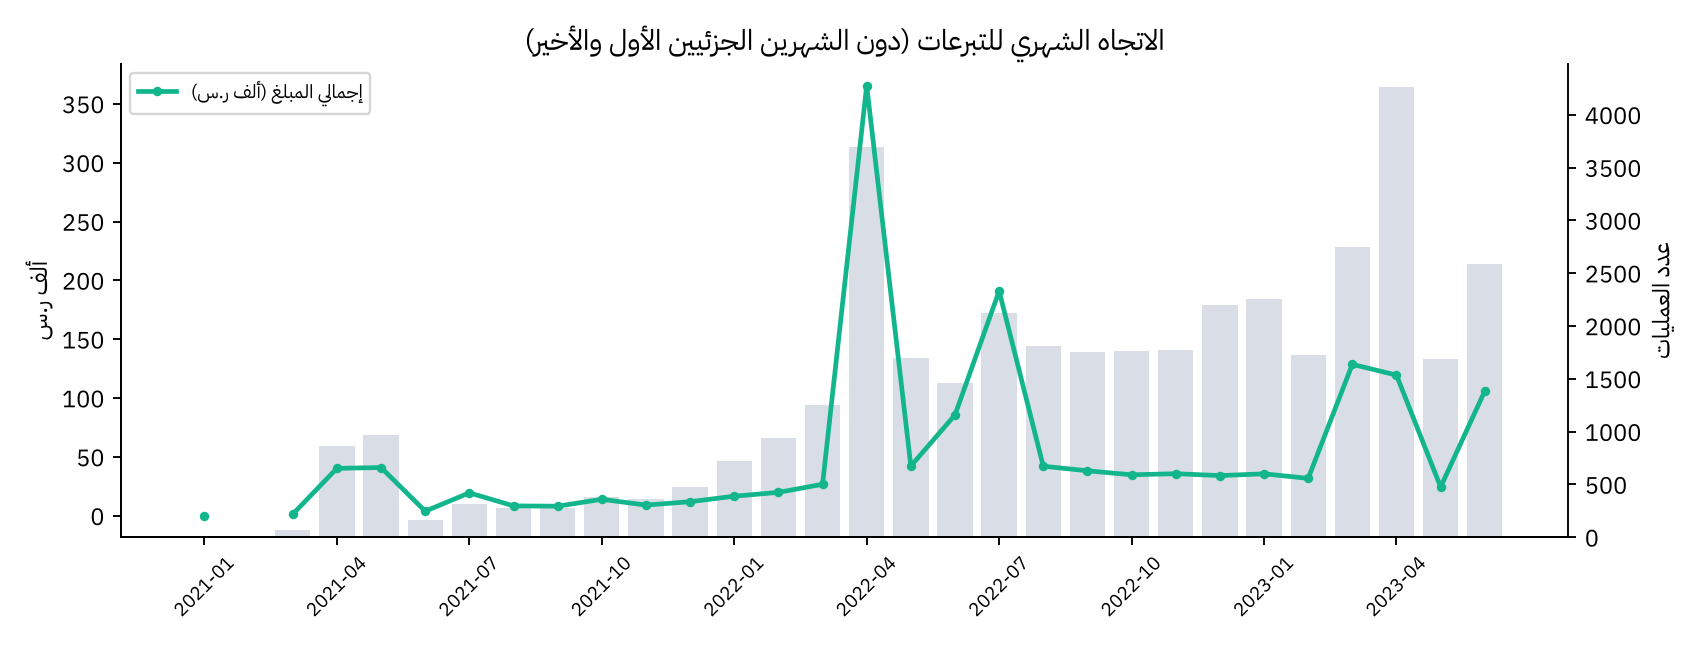

saved 02_amount_distribution.png


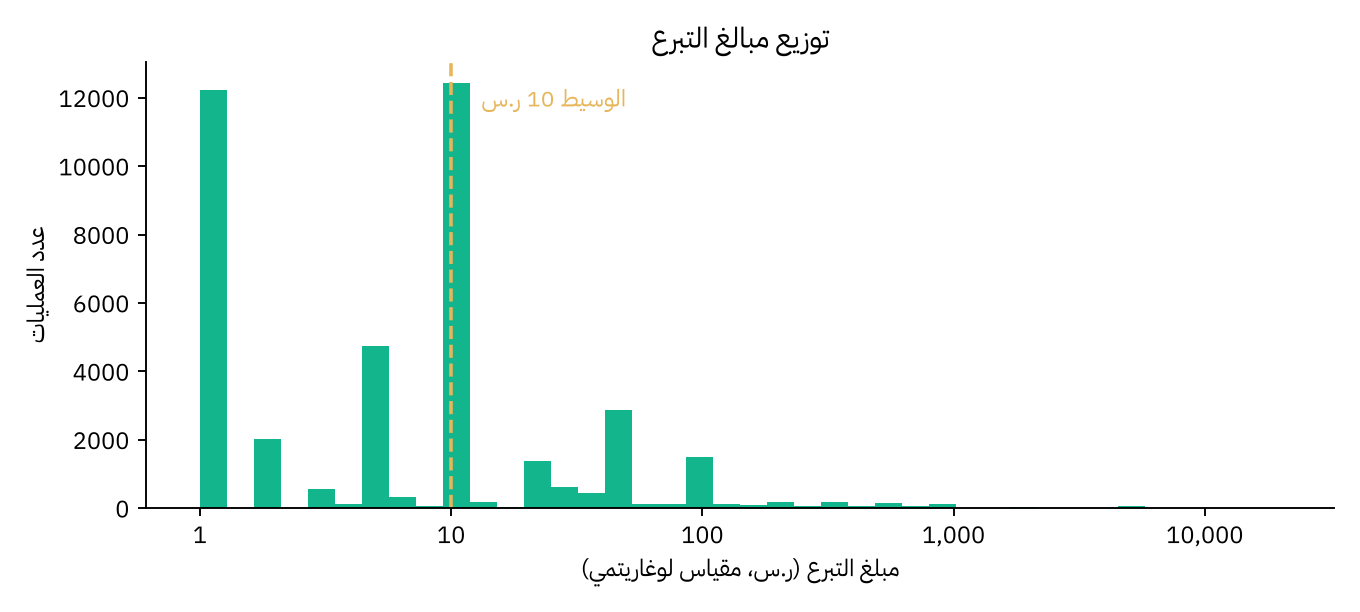

saved 03_top_initiatives.png


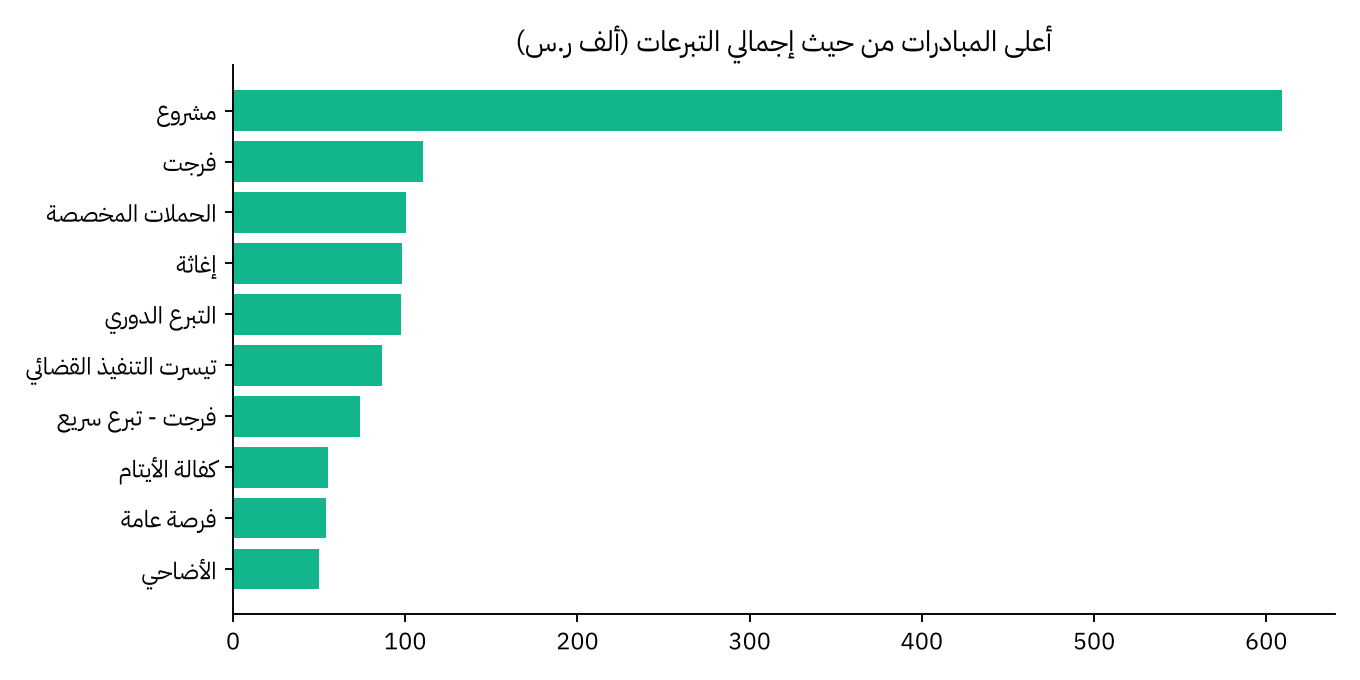

saved 04_payment_methods.png


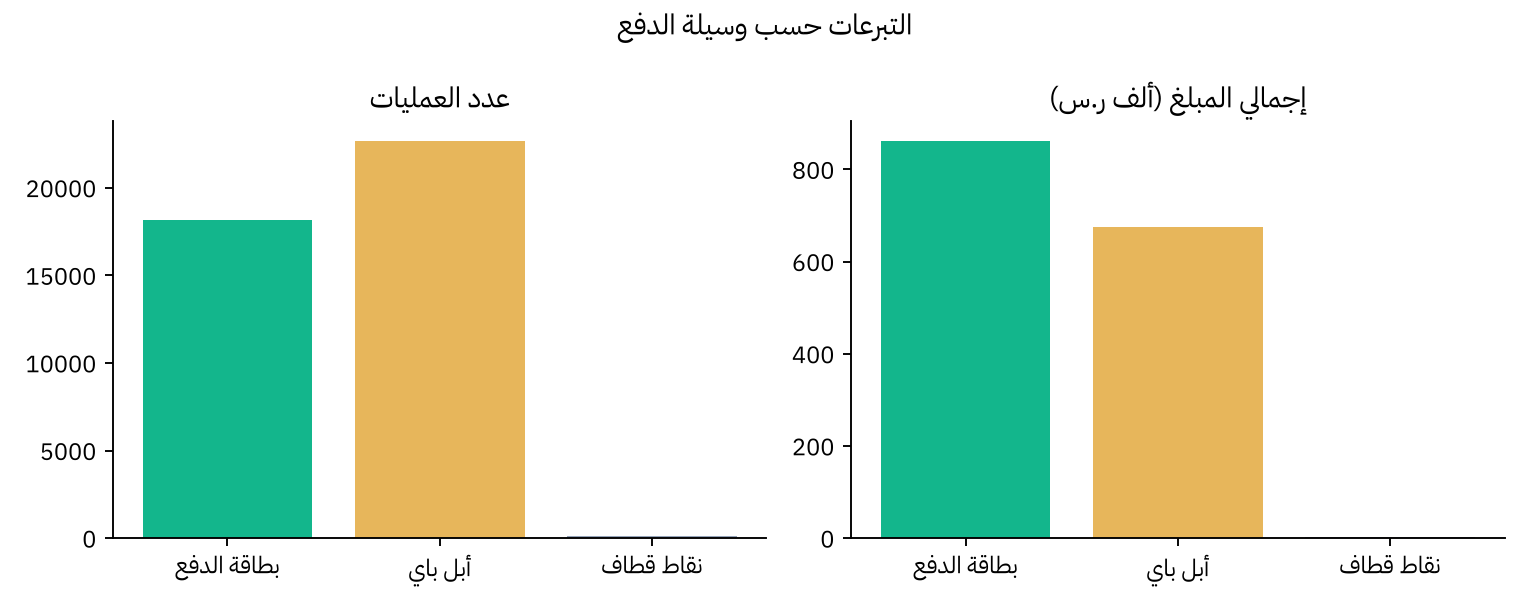

saved 05_donation_frequency.png


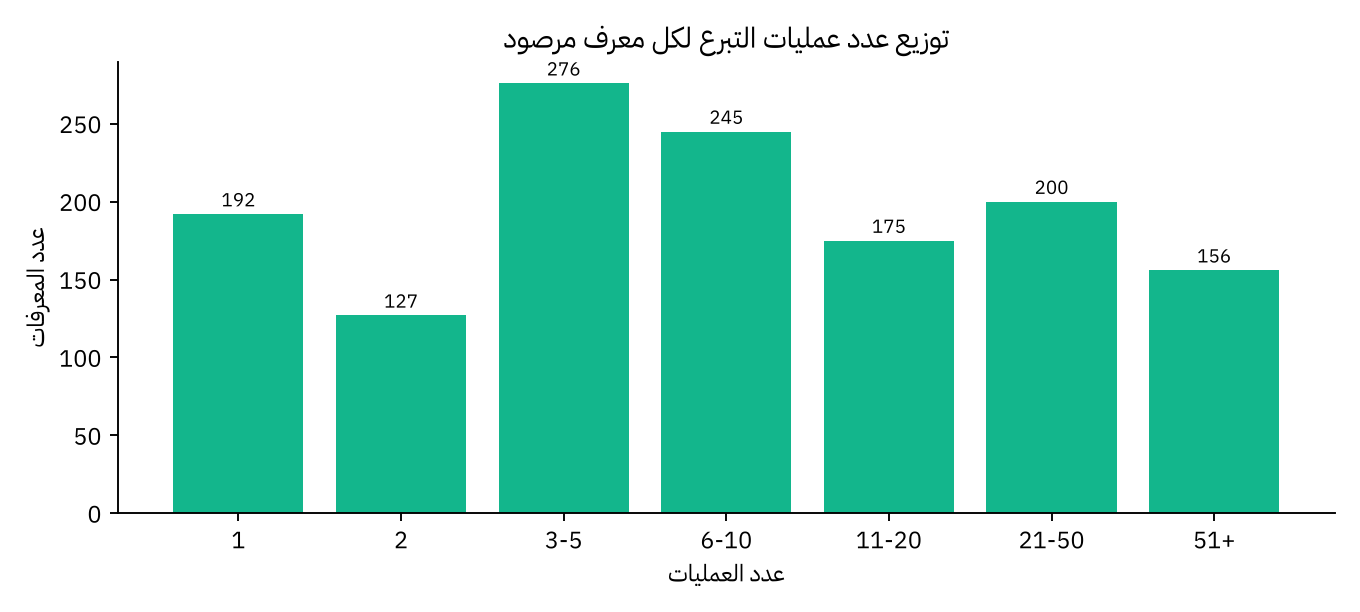

saved 06_activity_heatmap.png


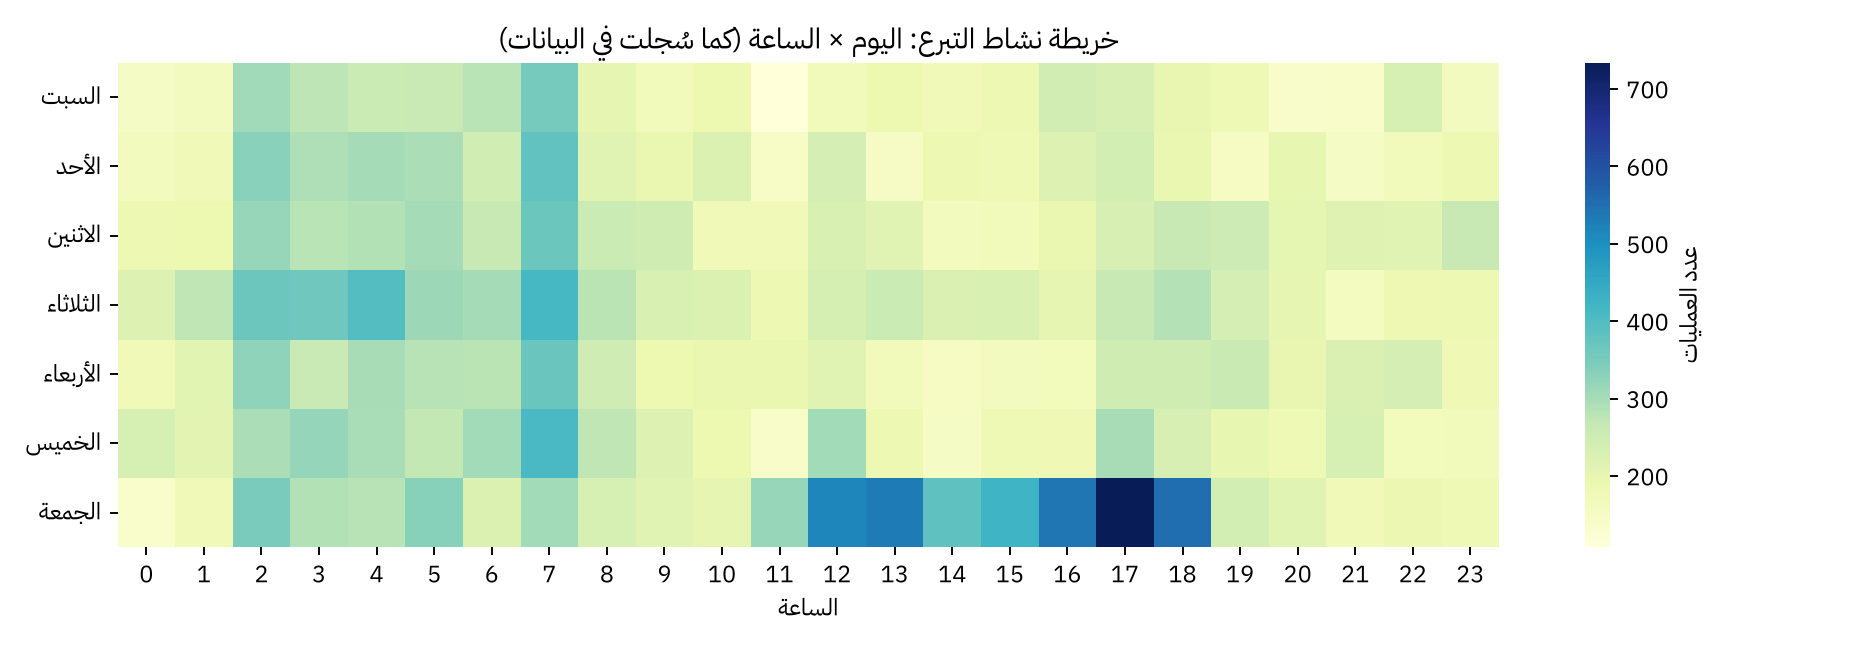

saved 07_top_opportunities.png


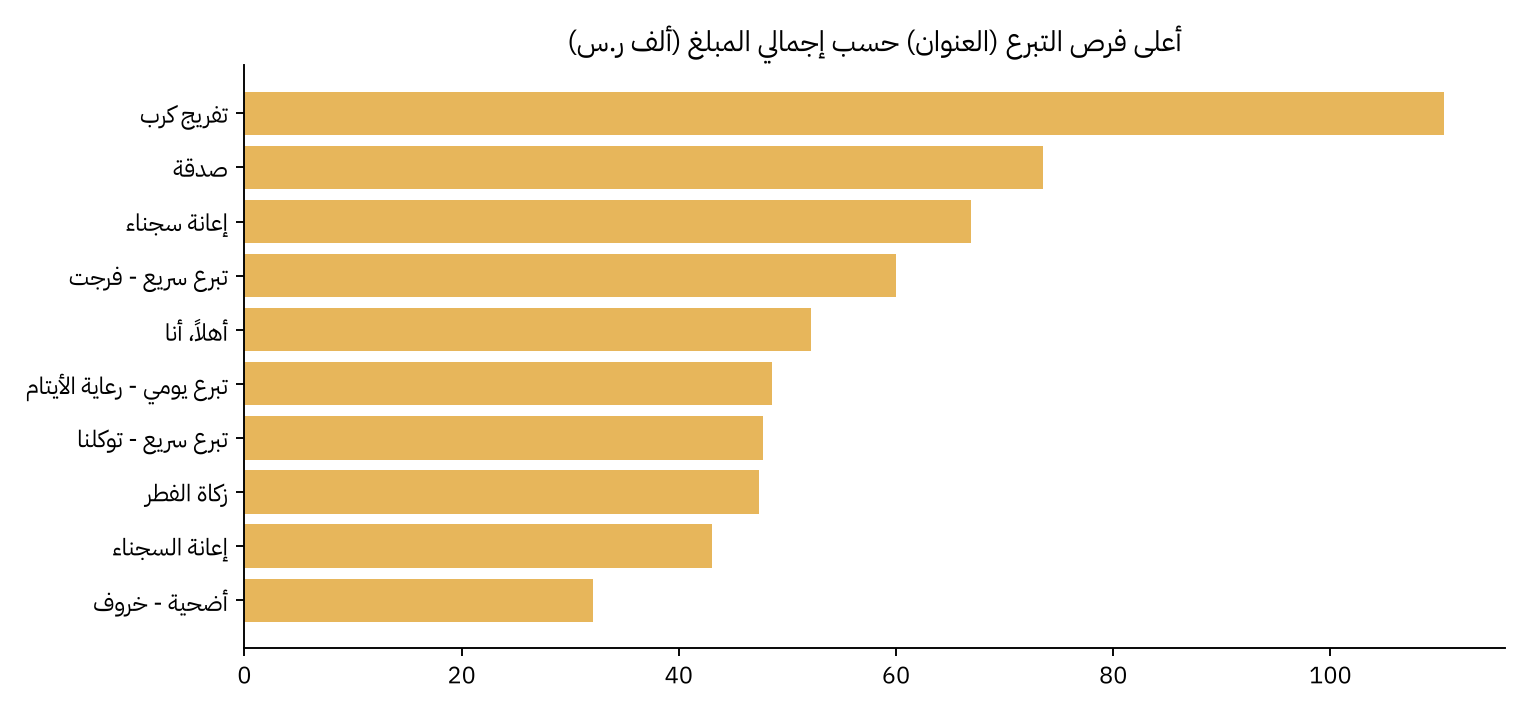

saved 08_avg_by_initiative.png


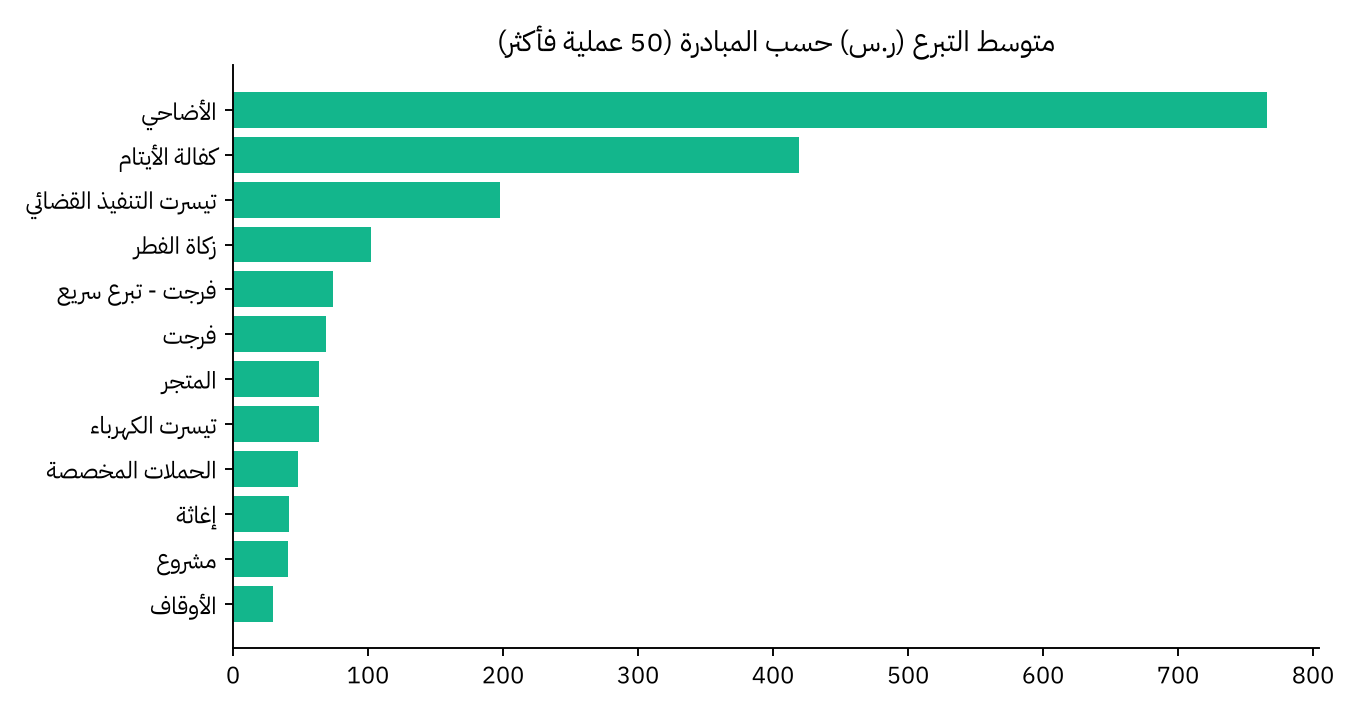

saved 10_yearly_comparison.png


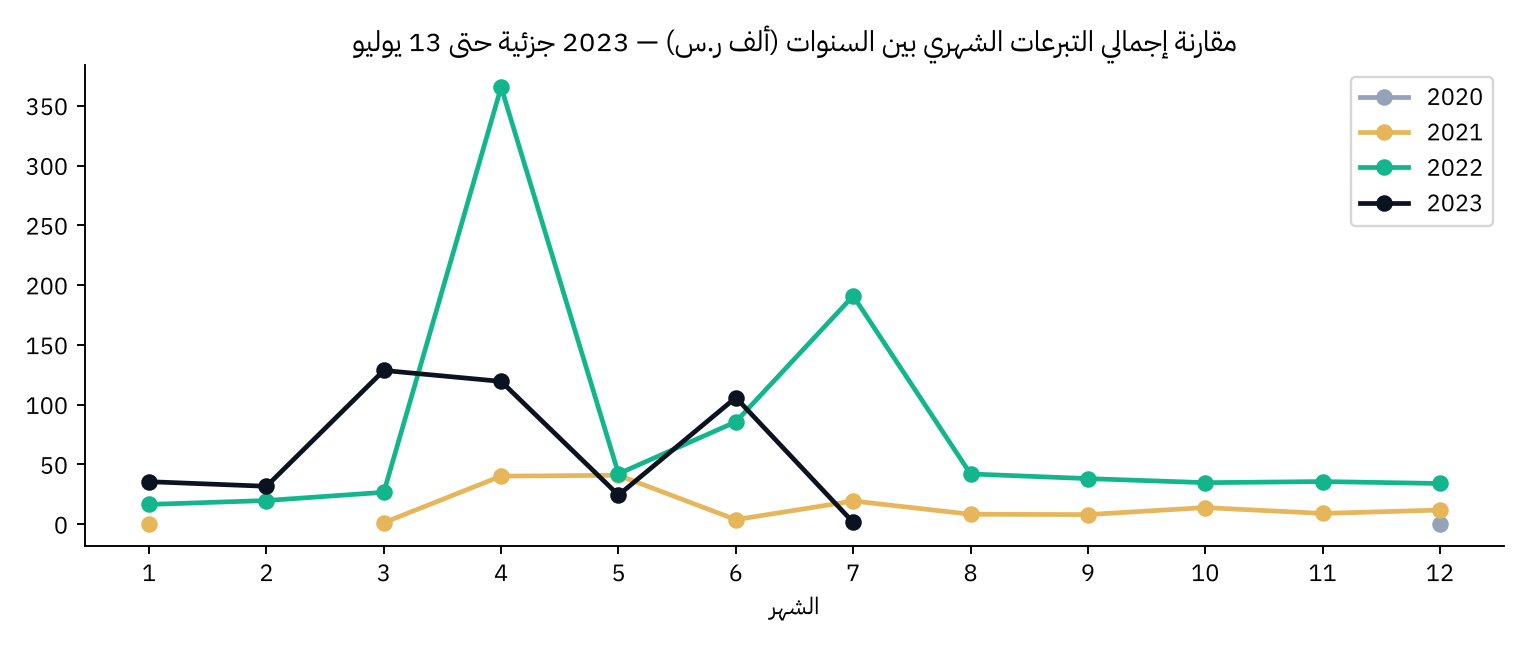

In [18]:
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG_DIR / name, dpi=170); plt.close(fig); print("saved", name)
    if "__file__" not in globals() and _InlineImage is not None:  # notebook run: show the figure inline
        display(_InlineImage(filename=str(FIG_DIR / name), width=760))
fm = mon[~mon.partial].set_index("year_month").reindex([str(x) for x in pd.period_range(mon.year_month.iloc[1], mon.year_month.iloc[-2], freq="M")]).rename_axis("year_month").reset_index()  # months with no records appear as gaps, not zeros
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(fm.year_month, fm.amount / 1000, color=GREEN, marker="o", ms=3, lw=2, label=ar("إجمالي المبلغ (ألف ر.س)"))
ax2 = ax.twinx(); ax2.bar(fm.year_month, fm.transactions, color=SLATE, alpha=.35, label=ar("عدد العمليات"))
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
ax.set_xticks(range(0, len(fm), 3)); ax.set_xticklabels(fm.year_month.iloc[::3], rotation=45, fontsize=8)
ax.set_title(ar("الاتجاه الشهري للتبرعات (دون الشهرين الجزئيين الأول والأخير)")); ax.set_ylabel(ar("ألف ر.س")); ax2.set_ylabel(ar("عدد العمليات"))
ax2.spines["right"].set_visible(True); ax.legend(loc="upper left", fontsize=8); save(fig, "01_monthly_trend.png")

fig, ax = plt.subplots(figsize=(8, 3.6)); ax.hist(np.log10(a), bins=40, color=GREEN)
ax.set_xticks([0, 1, 2, 3, 4]); ax.set_xticklabels(["1", "10", "100", "1,000", "10,000"]); ax.set_xlabel(ar("مبلغ التبرع (ر.س، مقياس لوغاريتمي)")); ax.set_ylabel(ar("عدد العمليات"))
ax.set_title(ar("توزيع مبالغ التبرع")); ax.axvline(np.log10(a.median()), color=GOLD, ls="--"); ax.text(np.log10(a.median()) + .12, ax.get_ylim()[1] * .9, ar(f"الوسيط {a.median():.0f} ر.س"), color=GOLD); save(fig, "02_amount_distribution.png")

top = ini.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4)); ax.barh([ar(x) for x in top.initiative], top.amount / 1000, color=GREEN)
ax.set_title(ar("أعلى المبادرات من حيث إجمالي التبرعات (ألف ر.س)")); save(fig, "03_top_initiatives.png")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6)); ax[0].bar([ar(shown(x)) for x in pay.payment_method], pay.transactions, color=[GREEN, GOLD, SLATE]); ax[0].set_title(ar("عدد العمليات"))
ax[1].bar([ar(shown(x)) for x in pay.payment_method], pay.amount / 1000, color=[GREEN, GOLD, SLATE]); ax[1].set_title(ar("إجمالي المبلغ (ألف ر.س)")); fig.suptitle(ar("التبرعات حسب وسيلة الدفع")); save(fig, "04_payment_methods.png")

fd = pd.Series(donor["freq_dist"]); fig, ax = plt.subplots(figsize=(8, 3.6)); ax.bar(fd.index.astype(str), fd.values, color=GREEN)
for i, v in enumerate(fd.values): ax.text(i, v + 5, f"{v:,}", ha="center", fontsize=8)
ax.set_title(ar("توزيع عدد عمليات التبرع لكل معرف مرصود")); ax.set_xlabel(ar("عدد العمليات")); ax.set_ylabel(ar("عدد المعرفات")); save(fig, "05_donation_frequency.png")

fig, ax = plt.subplots(figsize=(11, 3.8)); sns.heatmap(heat.rename(index=lambda s: ar(s)), cmap="YlGnBu", ax=ax, cbar_kws={"label": ar("عدد العمليات")})
ax.set_title(ar("خريطة نشاط التبرع: اليوم × الساعة (كما سُجلت في البيانات)")); ax.set_xlabel(ar("الساعة")); ax.set_ylabel(""); ax.tick_params(axis="y", rotation=0); ax.tick_params(axis="x", rotation=0); save(fig, "06_activity_heatmap.png")

tt = ttl.nlargest(10, "amount").iloc[::-1]; fig, ax = plt.subplots(figsize=(9, 4.2)); ax.barh([ar(x[:38]) for x in tt.title], tt.amount / 1000, color=GOLD)
ax.set_title(ar("أعلى فرص التبرع (العنوان) حسب إجمالي المبلغ (ألف ر.س)")); save(fig, "07_top_opportunities.png")

ai = ini[ini.transactions >= 50].sort_values("avg").tail(12); fig, ax = plt.subplots(figsize=(8, 4.2)); ax.barh([ar(x) for x in ai.initiative], ai.avg, color=GREEN)
ax.set_title(ar("متوسط التبرع (ر.س) حسب المبادرة (50 عملية فأكثر)")); save(fig, "08_avg_by_initiative.png")

yr = df.pivot_table(index="month", columns="year", values="amount", aggfunc="sum").reindex(range(1, 13)) / 1000
fig, ax = plt.subplots(figsize=(9, 3.8))
for y, col in zip(yr.columns, [SLATE, GOLD, GREEN, NAVY]):
    ax.plot(yr.index, yr[y], marker="o", label=str(y), color=col, lw=2)
ax.set_xticks(range(1, 13)); ax.set_title(ar("مقارنة إجمالي التبرعات الشهري بين السنوات (ألف ر.س) — 2023 جزئية حتى 13 يوليو")); ax.legend(); ax.set_xlabel(ar("الشهر")); save(fig, "10_yearly_comparison.png")

<div dir="rtl" style="direction:rtl; text-align:right">

## 5. تقسيم المعرّفات (RFM)
الخصائص: الحداثة، والتكرار، وإجمالي المبلغ، بعد تحويل لوغاريتمي وتوحيد للمقاييس.

يُختبر عدد الشرائح من 2 إلى 6 بمعيار Silhouette. سجّلت شريحتان أعلى قيمة، واعتُمدت ثلاث شرائح لتوفير تمييز قابل للتفسير في التواصل مع المتبرعين؛ فالاختيار عملي وليس الأفضل إحصائياً.

</div>

Silhouette: {2: 0.386, 3: 0.303, 4: 0.301, 5: 0.287, 6: 0.289} → k = 3 | stability ARI: {1: 1.0, 7: 1.0, 99: 1.0, 2024: 1.0}


,cluster,donors,recency_median,frequency_median,monetary_median,monetary_sum,frequency_sum,donor_share_pct,amount_share_pct,txn_share_pct,segment,description
0,0,522,324.5,2.0,31.5,33418.0,1577,38.1,2.2,3.9,منخفضو النشاط الأخير,منخفضو النشاط الأخير: 522 معرفاً (38.1%)، وسيط...
1,1,245,16.0,69.0,1225.0,1213913.0,31067,17.9,79.0,75.9,الأعلى مساهمة,الأعلى مساهمة: 245 معرفاً (17.9%)، وسيط التكرا...
2,2,604,84.0,10.0,227.0,290214.0,8286,44.1,18.9,20.2,المتكررون,المتكررون: 604 معرفاً (44.1%)، وسيط التكرار 10...


منخفضو النشاط الأخير: 522 معرفاً (38.1%)، وسيط التكرار 2 عملية، وسيط المبلغ الإجمالي 32 ر.س، وسيط الأيام منذ آخر تبرع 324، ويمثل 2.2% من إجمالي المبالغ.
الأعلى مساهمة: 245 معرفاً (17.9%)، وسيط التكرار 69 عملية، وسيط المبلغ الإجمالي 1,225 ر.س، وسيط الأيام منذ آخر تبرع 16، ويمثل 79.0% من إجمالي المبالغ.
المتكررون: 604 معرفاً (44.1%)، وسيط التكرار 10 عملية، وسيط المبلغ الإجمالي 227 ر.س، وسيط الأيام منذ آخر تبرع 84، ويمثل 18.9% من إجمالي المبالغ.


saved 09_donor_segments.png


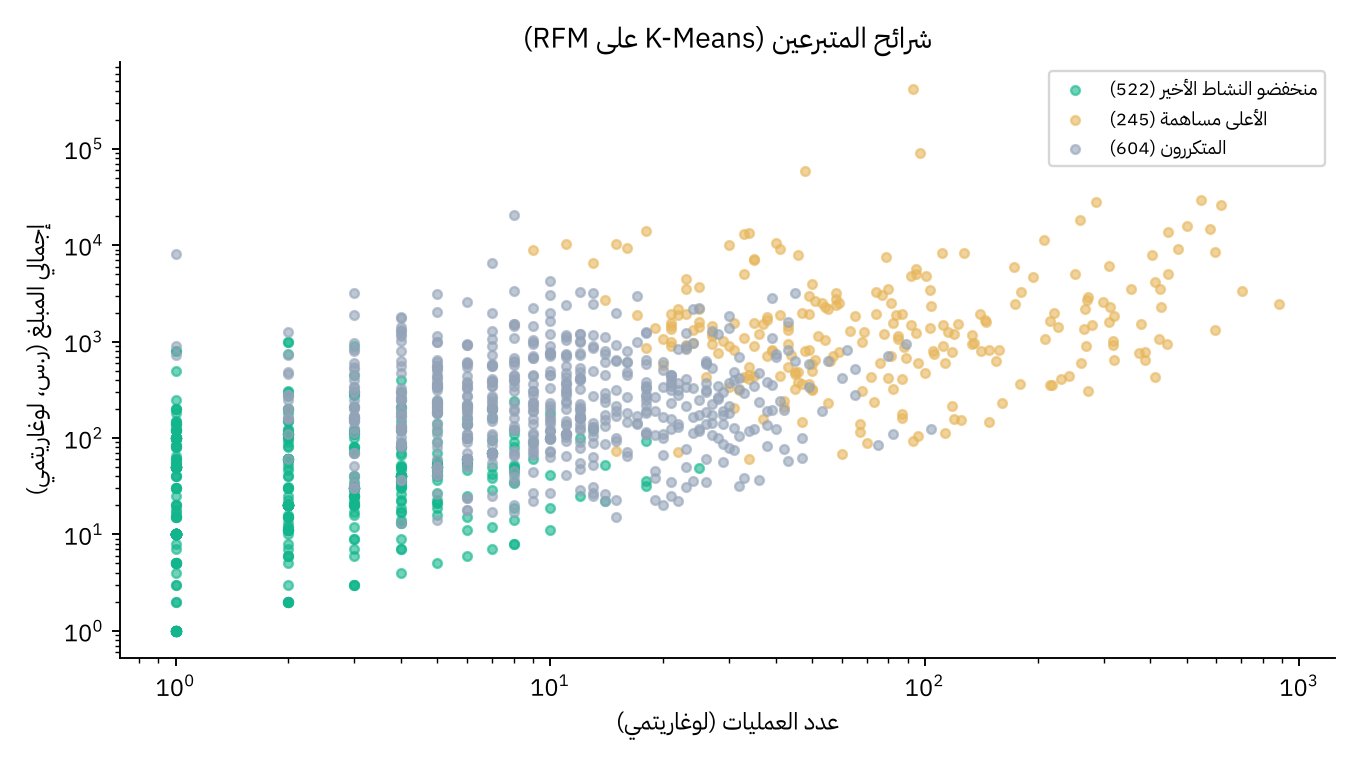

In [19]:
X = np.log1p(g[["recency", "frequency", "monetary"]]); Xs = StandardScaler().fit_transform(X)
sil = {k: float(silhouette_score(Xs, KMeans(k, n_init=20, random_state=SEED).fit_predict(Xs))) for k in range(2, 7)}
best_k = max((k for k in sil if k >= 3), key=sil.get)
km = KMeans(best_k, n_init=20, random_state=SEED).fit(Xs); g["cluster"] = km.labels_
# stability: re-fit with other seeds and compare the partitions (1.0 = identical grouping)
STAB_SEEDS = [1, 7, 99, 2024]
stab = {int(s): float(adjusted_rand_score(km.labels_, KMeans(best_k, n_init=20, random_state=s).fit_predict(Xs))) for s in STAB_SEEDS}
print("Silhouette:", {k: round(v, 3) for k, v in sil.items()}, "→ k =", best_k, "| stability ARI:", {k: round(v, 3) for k, v in stab.items()})
cs = g.groupby("cluster").agg(donors=("frequency", "size"), recency_median=("recency", "median"), frequency_median=("frequency", "median"),
                              monetary_median=("monetary", "median"), monetary_sum=("monetary", "sum"), frequency_sum=("frequency", "sum")).reset_index()
cs["donor_share_pct"] = cs.donors / tot_users * 100; cs["amount_share_pct"] = cs.monetary_sum / tot * 100; cs["txn_share_pct"] = cs.frequency_sum / n * 100
# rule-based naming: highest median amount, then highest median frequency, then longest inactivity
names, left = {}, set(cs.cluster)
c = cs.set_index("cluster")
top_m = c.loc[list(left)].monetary_median.idxmax(); names[top_m] = "الأعلى مساهمة"; left.discard(top_m)
if left: top_f = c.loc[list(left)].frequency_median.idxmax(); names[top_f] = "المتكررون"; left.discard(top_f)
if left: top_r = c.loc[list(left)].recency_median.idxmax(); names[top_r] = "منخفضو النشاط الأخير"; left.discard(top_r)
for i, k in enumerate(sorted(left)): names[k] = "عرضيون" + ("" if len(left) == 1 else f" {i + 1}")
cs["segment"] = cs.cluster.map(names)
desc = []
for _, row in cs.iterrows():
    desc.append(f"{row.segment}: {int(row.donors):,} معرفاً ({row.donor_share_pct:.1f}%)، وسيط التكرار {row.frequency_median:.0f} عملية، وسيط المبلغ الإجمالي {row.monetary_median:,.0f} ر.س، وسيط الأيام منذ آخر تبرع {row.recency_median:.0f}، ويمثل {row.amount_share_pct:.1f}% من إجمالي المبالغ.")
cs["description"] = desc
M["segmentation"] = dict(k=int(best_k), silhouette_by_k=sil, silhouette_chosen=sil[best_k],
                         stability_ari=stab, stability_ari_min=float(min(stab.values())), features=["recency", "frequency", "monetary (log1p + standardized)"],
                         segments=json.loads(cs.drop(columns=["cluster"]).to_json(orient="records")))
display(cs.round(1)); print("\n".join(desc))
g["segment"] = g.cluster.map(names)
fig, ax = plt.subplots(figsize=(8, 4.5))
for sname, col in zip(cs.segment, [GREEN, GOLD, SLATE, NAVY, "#C0504D", "#7B68EE"]):
    s = g[g.segment == sname]; ax.scatter(s.frequency, s.monetary, s=14, alpha=.6, color=col, label=ar(f"{sname} ({len(s):,})"))
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(ar("عدد العمليات (لوغاريتمي)")); ax.set_ylabel(ar("إجمالي المبلغ (ر.س، لوغاريتمي)"))
ax.set_title(ar("شرائح المتبرعين (K-Means على RFM)")); ax.legend(fontsize=8); save(fig, "09_donor_segments.png")

saved 11_time_to_second_gift.png


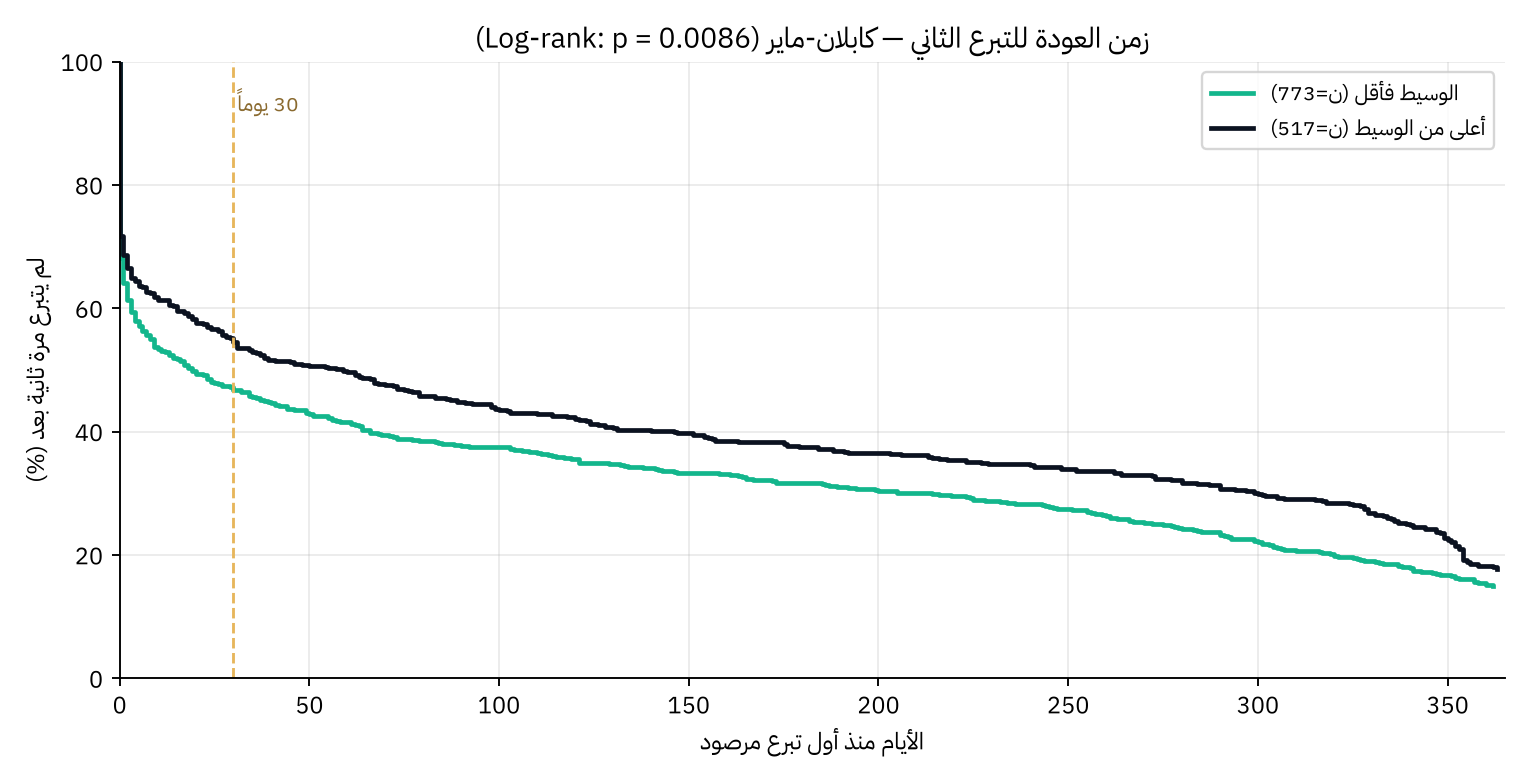

In [20]:
fig, ax = plt.subplots(figsize=(9, 4.6))
_g = [g for g in SURV["groups"] if g["name"].startswith("مبلغ أول تبرع")][0]
for lv, col in zip(_g["levels"], ["#13B68C", "#0B1220"]):
    d = [0] + [c["day"] for c in lv["curve"]]
    v = [1.0] + [c["survival"] for c in lv["curve"]]
    ax.step(d, [x * 100 for x in v], where="post", color=col, lw=2,
            label=ar(f"{lv['name']} (ن={lv['n']:,})"))
ax.axvline(30, color="#E7B65B", ls="--", lw=1.2)
ax.text(31, 92, ar("30 يوماً"), fontsize=9, color="#8A6A2F")
ax.set_xlim(0, 365); ax.set_ylim(0, 100)
ax.set_xlabel(ar("الأيام منذ أول تبرع مرصود")); ax.set_ylabel(ar("لم يتبرع مرة ثانية بعد (%)"))
_t = SURV["tests"][_g["name"]]
ax.set_title(ar(f"زمن العودة للتبرع الثاني — كابلان-ماير (Log-rank: p = {_t['p_value']:.4f})"))
ax.legend(fontsize=9); ax.grid(alpha=.25)
save(fig, "11_time_to_second_gift.png")

saved 12_cox_hazard_ratios.png


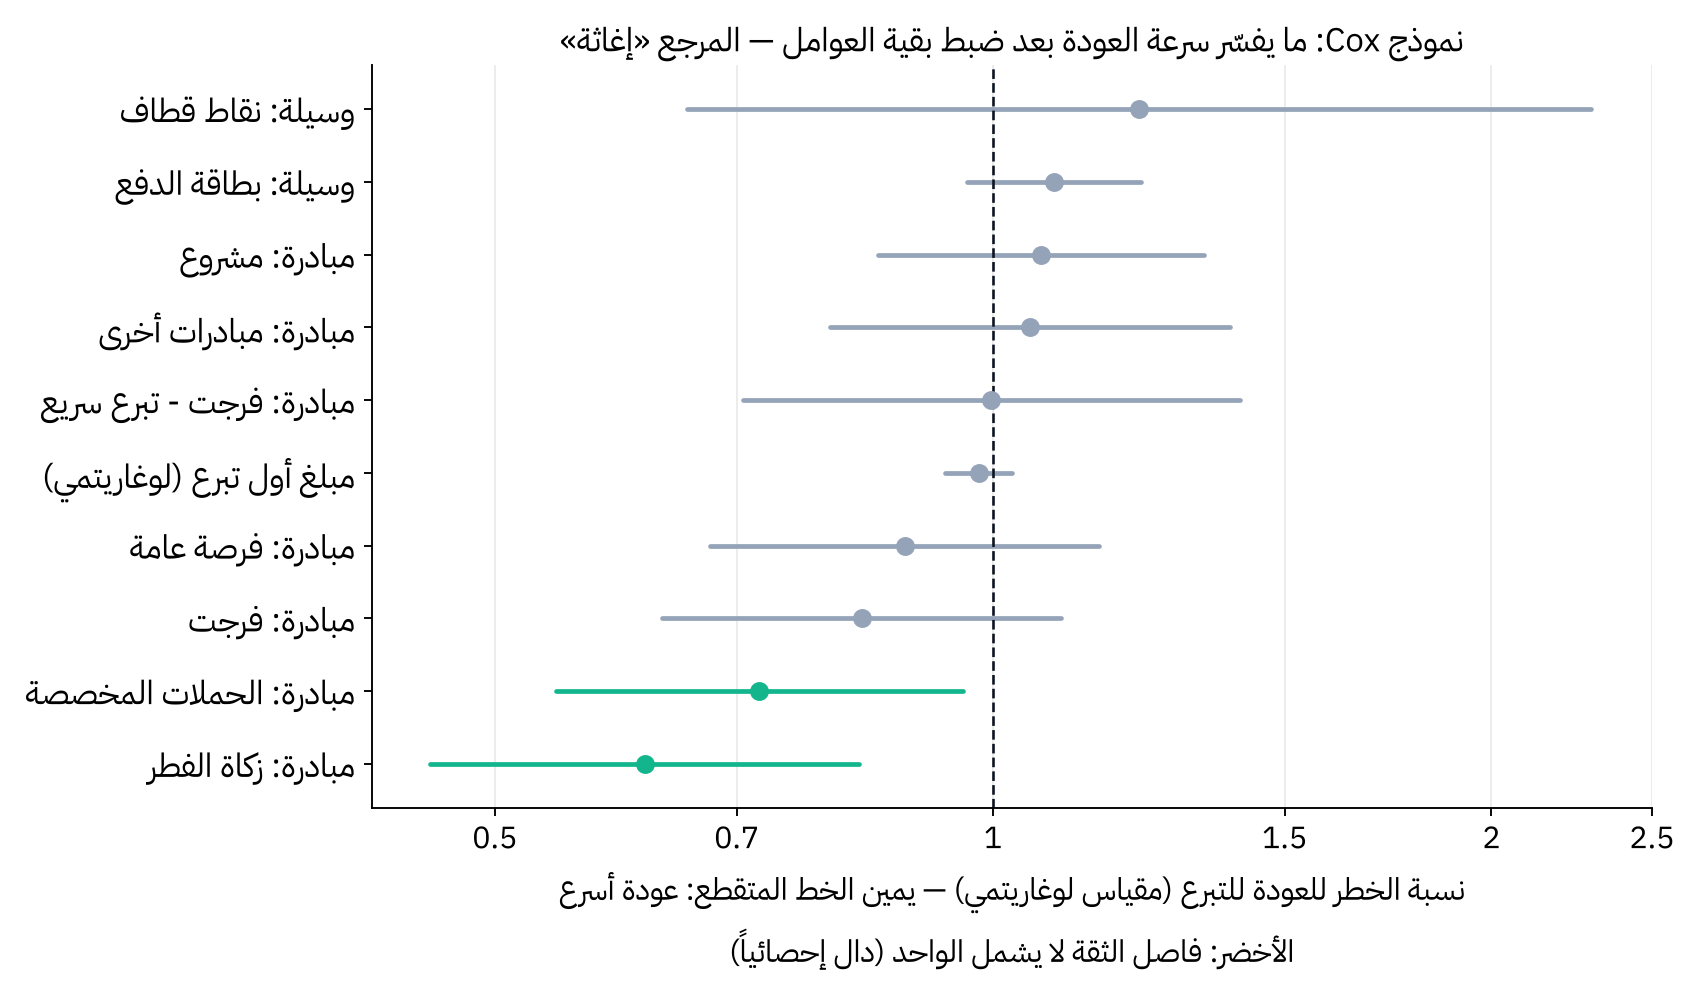

In [21]:
_lbl = {"log_first_amount": "مبلغ أول تبرع (لوغاريتمي)"}
_terms = sorted(COX["terms"], key=lambda t: t["hazard_ratio"])
_names = [_lbl.get(t["term"], t["term"].replace("ini_", "مبادرة: ").replace("pay_", "وسيلة: ")) for t in _terms]
fig, ax = plt.subplots(figsize=(10, 0.40 * len(_terms) + 1.9))
for i, t in enumerate(_terms):
    c = GREEN if t["significant"] else SLATE
    ax.plot(t["ci95"], [i, i], color=c, lw=2, solid_capstyle="round")
    ax.plot([t["hazard_ratio"]], [i], "o", color=c, ms=7, zorder=3)
ax.axvline(1, color=NAVY, ls="--", lw=1.1)
ax.set_yticks(range(len(_terms))); ax.set_yticklabels([ar(x) for x in _names], fontsize=14)
ax.set_xscale("log")
_ticks = [0.5, 0.7, 1.0, 1.5, 2.0, 2.5]
ax.set_xticks(_ticks); ax.set_xticklabels([f"{t:g}" for t in _ticks], fontsize=13); ax.minorticks_off()
ax.set_ylim(-0.6, len(_terms) - 0.4)
ax.set_title(ar(f"نموذج Cox: ما يفسّر سرعة العودة بعد ضبط بقية العوامل — المرجع «{COX['reference']['ini']}»"), fontsize=14)
ax.set_xlabel(ar("نسبة الخطر للعودة للتبرع (مقياس لوغاريتمي) — يمين الخط المتقطع: عودة أسرع\nالأخضر: فاصل الثقة لا يشمل الواحد (دال إحصائياً)"), fontsize=13)
ax.grid(axis="x", alpha=.25)
save(fig, "12_cox_hazard_ratios.png")

<div dir="rtl" style="direction:rtl; text-align:right">

## 6. التنبؤ الاستكشافي بعودة المتبرع
**الهدف:** قياس ما إذا كانت مؤشرات السلوك السابق تضيف قدرة تنبؤية على عودة المعرّف للتبرع، مقارنةً بقاعدة بسيطة هي عدد تبرعاته السابقة.

- **النتيجة المستهدفة:** 1 إذا سجّل المعرّف عملية تبرع واحدة على الأقل خلال 90 يوماً بعد تاريخ القطع، وإلا 0.
- **الفئة:** المعرّفات التي لها تبرع واحد على الأقل قبل تاريخ القطع، وتُحسب خصائصها من عملياتها السابقة للقطع فقط.
- **التقسيم الزمني:** ثلاث نوافذ متتابعة لا تتداخل للتدريب ثم التحقق ثم الاختبار.
- **التقييم:** تُقارَن النماذج على مجموعة التحقق فقط، ثم يُعاد تدريب النموذج المختار ويُقيَّم مرة واحدة على مجموعة الاختبار بمقياس AUC.

التقييم على نافذة اختبار واحدة؛ فالنتيجة استكشافية ولا تثبت تفوقاً إحصائياً ولا دقة مستقبلية.

</div>

In [22]:
END = df.created_at.max(); HORIZON = 90; H = pd.Timedelta(days=HORIZON)
CUTS = {"train": pd.Timestamp("2022-10-16"), "validation": pd.Timestamp("2023-01-14"), "test": pd.Timestamp("2023-04-14")}
assert CUTS["train"] < CUTS["validation"] < CUTS["test"]
assert CUTS["train"] + H == CUTS["validation"] and CUTS["validation"] + H == CUTS["test"]   # consecutive, non-overlapping windows
assert CUTS["test"] + H <= END                                                                # the test label window is fully observed
FEATURES = ["recency", "frequency", "monetary", "avg_amount", "n_init", "active_months", "tenure", "last30"]
def feats(cut):
    h = df[df.created_at < cut]; gg = h.groupby("user_id")                                    # features: transactions before the cutoff only
    f = pd.DataFrame({"recency": (cut - gg.created_at.max()).dt.days, "frequency": gg.size(), "monetary": gg.amount.sum(), "avg_amount": gg.amount.mean(),
                      "n_init": gg.initiative.nunique(), "active_months": gg.year_month.nunique(), "tenure": (cut - gg.created_at.min()).dt.days,
                      "last30": h[h.created_at >= cut - pd.Timedelta(days=30)].groupby("user_id").size()}).fillna({"last30": 0})
    fut = df[(df.created_at >= cut) & (df.created_at < cut + H)].user_id.unique()              # label: any donation within 90 days after the cutoff
    f["y"] = f.index.isin(fut).astype(int); return f
sets = {k: feats(c) for k, c in CUTS.items()}
prep = lambda d: np.log1p(d[FEATURES])
MODELS = {"Logistic Regression": lambda: LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
          "Gradient Boosting": lambda: GradientBoostingClassifier(random_state=SEED, max_depth=3, n_estimators=150)}
def fit_eval(name, train_parts, eval_df):
    Xtr = pd.concat([prep(p) for p in train_parts]); ytr = pd.concat([p.y for p in train_parts])
    sc = StandardScaler().fit(Xtr); mdl = MODELS[name]().fit(sc.transform(Xtr), ytr)
    p = mdl.predict_proba(sc.transform(prep(eval_df)))[:, 1]
    return dict(auc=float(roc_auc_score(eval_df.y, p)), precision=float(precision_score(eval_df.y, p > .5, zero_division=0)), recall=float(recall_score(eval_df.y, p > .5, zero_division=0)))
val_res = {n: fit_eval(n, [sets["train"]], sets["validation"]) for n in MODELS}
best = max(val_res, key=lambda k: val_res[k]["auc"])                                          # model selection on the validation set only
test_res = fit_eval(best, [sets["train"], sets["validation"]], sets["test"])                  # refit on train + validation, then a single test evaluation
base = dict(name="عدد التبرعات", validation_auc=float(roc_auc_score(sets["validation"].y, sets["validation"].frequency)),
            test_auc=float(roc_auc_score(sets["test"].y, sets["test"].frequency)))
margin = test_res["auc"] - base["test_auc"]
# paired bootstrap on the test window: does the gap exceed sampling noise?
def _test_scores():
    Xtr = pd.concat([prep(sets["train"]), prep(sets["validation"])]); ytr = pd.concat([sets["train"].y, sets["validation"].y])
    sc = StandardScaler().fit(Xtr); mdl = MODELS[best]().fit(sc.transform(Xtr), ytr)
    return mdl.predict_proba(sc.transform(prep(sets["test"])))[:, 1], sets["test"].frequency.values, sets["test"].y.values
_pm, _pb, _y = _test_scores()
_rng = np.random.default_rng(SEED); _d = []
for _ in range(2000):
    _i = _rng.integers(0, len(_y), len(_y))
    if len(np.unique(_y[_i])) < 2: continue
    _d.append(roc_auc_score(_y[_i], _pm[_i]) - roc_auc_score(_y[_i], _pb[_i]))
_d = np.array(_d); _lo, _hi = (float(np.percentile(_d, 2.5)), float(np.percentile(_d, 97.5)))
boot = dict(resamples=int(len(_d)), ci95=[_lo, _hi], excludes_zero=bool(_lo > 0), share_model_not_better=float((_d <= 0).mean()))
pred = dict(horizon_days=HORIZON, cutoffs={k: str(v.date()) for k, v in CUTS.items()},
            label_windows={k: [str(v.date()), str((v + H).date())] for k, v in CUTS.items()},
            sizes={k: int(len(v)) for k, v in sets.items()}, positive_rate={k: float(v.y.mean()) for k, v in sets.items()},
            validation=val_res, chosen_model=best, selection_rule="أعلى AUC على مجموعة التحقق فقط", test=dict(model=best, **test_res), baseline=base,
            test_margin_over_baseline=float(margin), bootstrap=boot,
            verdict=("تحسن محدود عن خط الأساس على نافذة اختبار واحدة" if margin > .02 else "لا فرق واضح عن خط الأساس على نافذة اختبار واحدة"),
            note=(f"يتجاوز الفرق ضجيج المعاينة داخل نافذة الاختبار (فاصل ثقة 95% بإعادة المعاينة: {_lo:+.3f} إلى {_hi:+.3f})"
                  if boot["excludes_zero"] else
                  f"لا يتجاوز الفرق ضجيج المعاينة داخل نافذة الاختبار (فاصل ثقة 95%: {_lo:+.3f} إلى {_hi:+.3f})")
                 + "، ولا يثبت ذلك ثباته عبر فترات أخرى لأن التقييم على نافذة واحدة.",
            base_rate_note=("تتفاوت نسبة العائدين بين النوافذ، فمقارنة الدقة والاسترجاع بين نافذتين غير دقيقة لاختلاف القاعدة؛ "
                            "والمقارنة المعتمدة هي AUC بين النموذج وخط الأساس داخل النافذة نفسها، وتلزم إعادة معايرة العتبة عند أي استخدام تشغيلي."))
M["prediction"] = pred; print(json.dumps(pred, ensure_ascii=False, indent=1))

{
 "horizon_days": 90,
 "cutoffs": {
  "train": "2022-10-16",
  "validation": "2023-01-14",
  "test": "2023-04-14"
 },
 "label_windows": {
  "train": [
   "2022-10-16",
   "2023-01-14"
  ],
  "validation": [
   "2023-01-14",
   "2023-04-14"
  ],
  "test": [
   "2023-04-14",
   "2023-07-13"
  ]
 },
 "sizes": {
  "train": 1168,
  "validation": 1219,
  "test": 1288
 },
 "positive_rate": {
  "train": 0.3133561643835616,
  "validation": 0.4741591468416735,
  "test": 0.5279503105590062
 },
 "validation": {
  "Logistic Regression": {
   "auc": 0.7737990488477671,
   "precision": 0.7602905569007264,
   "recall": 0.5432525951557093
  },
  "Gradient Boosting": {
   "auc": 0.7131307051590021,
   "precision": 0.8227272727272728,
   "recall": 0.31314878892733566
  }
 },
 "chosen_model": "Logistic Regression",
 "selection_rule": "أعلى AUC على مجموعة التحقق فقط",
 "test": {
  "model": "Logistic Regression",
  "auc": 0.7286813080495356,
  "precision": 0.6866359447004609,
  "recall": 0.6573529411764706

<div dir="rtl" style="direction:rtl; text-align:right">

## 7. التوصيات وخطط المتابعة
تُولَّد التوصيات بقواعد معلنة، وتحمل كل توصية: الملاحظة، والمؤشر الداعم، والتفسير المحتمل، والإجراء المقترح، وحدّ الاستنتاج.

تُحدَّد الأولوية بنسبة إجمالي المبالغ التي يمسّها الموضوع: 10% فأكثر مرتفعة، ومن 3% إلى أقل من 10% متوسطة، وأقل من 3% منخفضة؛ وهي لا تمثّل تقديراً للعائد أو لسهولة التنفيذ.

</div>

In [23]:
def prio(share): return ("مرتفعة", "high") if share >= 10 else (("متوسطة", "medium") if share >= 3 else ("منخفضة", "low"))
INS = []
def add(key, title, obs, metric, interp, action, limit, share):
    p, pk = prio(share); INS.append(dict(id=key, title=title, observation=obs, metric=metric, interpretation=interp, action=action, limitation=limit,
                                         priority=p, priority_key=pk, affected_amount_share_pct=round(float(share), 1)))
f = lambda x, d=0: f"{x:,.{d}f}"
# 1) concentration of amounts in a single identifier
d1 = donor["top1_donor_amount_share_pct"]
add("concentration", "اعتماد مرتفع على معرّف متبرع واحد",
    f"معرّف واحد يمثل {d1:.1f}% من إجمالي المبالغ المرصودة عبر {donor['top1_donor_transactions']} عملية، وأعلى 1% من المعرفات تمثل {donor['top1pct_donors_amount_share_pct']:.1f}%.",
    f"متوسط التبرع {f(overview['mean'],1)} ر.س مع المعرف الأكبر و{f(donor['mean_txn_without_top1'],1)} ر.س بدونه.",
    "التركّز العالي يجعل الأرقام الإجمالية حساسة لسلوك جهة واحدة، وقد يكون المعرف مؤسسياً أو وسيطاً (غير مؤكد من البيانات).",
    "التحقق من طبيعة المعرف مع فريق البيانات، وعرض المؤشرات بوسيط المبلغ وبالتحليل مع/بدون المعرف، وبناء خطة تنويع لقاعدة المتبرعين.",
    "لا تتضمن البيانات هوية المتبرع أو نوعه، والعينة قد لا تمثل المنصة.", d1)
# 2) recurring donations: high volume, low amounts
rec = ini[ini.initiative == "التبرع الدوري"]
if len(rec):
    rr = rec.iloc[0]
    add("recurring", "التبرع الدوري: عدد كبير بمبالغ صغيرة",
        f"مبادرة «التبرع الدوري» تمثل {rr.txn_share_pct:.1f}% من العمليات و{rr.amount_share_pct:.1f}% فقط من المبالغ.",
        f"متوسط العملية {rr.avg:.1f} ر.س مقابل {overview['mean']:.1f} ر.س للعينة كلها.",
        "المساهمة المالية تتكوّن من تبرعات صغيرة متكررة تعطي انتظاماً في التدفق أكثر مما تعطي قيمة لكل عملية (تفسير محتمل).",
        "اختبار رفع القيمة تدريجياً (اقتراح مبالغ أعلى قليلاً عند التجديد) وحملات لتحويل المتبرعين لمرة واحدة إلى دوريين، مع قياس أثر كل تجربة.",
        "لا تحدد البيانات هل العمليات اشتراكات آلية أم تبرعات يدوية متتالية.", rr.amount_share_pct)
# 3) peak month
ok = mon[(~mon.partial) & (~mon.low_volume)]; top3 = "، ".join(ok.nlargest(3, "transactions").year_month); medn = ok.transactions.median(); pk_ = ok.loc[ok.transactions.idxmax()]
add("seasonal_peak", f"ذروة نشاط واضحة في {pk_.year_month}",
    f"سجّل شهر {pk_.year_month} {int(pk_.transactions):,} عملية، أي {pk_.transactions / medn:.1f} ضعف وسيط الأشهر المكتملة ({f(medn)}).",
    f"إجمالي الشهر {f(pk_.amount)} ر.س ({pk_.amount / tot * 100:.1f}% من الإجمالي).",
    f"أعلى الأشهر نشاطاً: {top3}. " + ("أبريل 2022 وأبريل 2023 يتزامنان مع شهر رمضان في التقويم، لكن البيانات لا تثبت أن الموسم هو السبب." if any(m.endswith("-04") for m in top3.split("، ")) else "البيانات لا تثبت سبب الارتفاع."),
    "تخطيط حملات مسبقة قبل المواسم المرصودة وقياس الفرق بعد التجربة، وتجهيز الطاقة التشغيلية لاستقبال الذروة.",
    "ذروة واحدة أو اثنتان لا تكفيان لإثبات نمط موسمي مستقر.", pk_.amount / tot * 100)
# 4) one-time donors
one = g[g.frequency == 1]
add("one_time", f"{len(one) / tot_users * 100:.0f}% من المعرفات المرصودة تبرعت مرة واحدة فقط",
    f"{len(one):,} معرفاً ({len(one) / tot_users * 100:.1f}%) ظهر في عملية واحدة فقط.",
    f"مساهمتهم {one.monetary.sum() / tot * 100:.1f}% من المبالغ؛ ونسبة المتكررين {donor['repeat_rate_pct']:.1f}%.",
    "مجال لرحلة «التبرع الثاني»، لكن العينة قد تخفي تبرعات سابقة أو لاحقة للمعرف خارجها.",
    "تجربة رسالة شكر وتذكير بعد أول تبرع مع عرض مبادرة مشابهة، ومقارنة معدل التبرع الثاني بين مجموعة تجريبية وضابطة.",
    "المتكرر هنا يعني ظهور المعرف أكثر من مرة داخل العينة فقط.", one.monetary.sum() / tot * 100)
# 5) repeat donors whose activity stopped
dorm = g[(g.frequency >= 3) & (g.recency > 90)]
add("dormant", "متبرعون متكررون خفّ نشاطهم المرصود",
    f"{len(dorm):,} معرفاً سبق أن تبرع 3 مرات فأكثر لم يظهر خلال آخر 90 يوماً من العينة.",
    f"يمثلون {dorm.monetary.sum() / tot * 100:.1f}% من المبالغ المرصودة.",
    "انقطاع مرصود وليس مؤكداً (قد يكونون تبرعوا عبر قناة أخرى أو انتهت مواسم تبرعهم).",
    "حملة استرجاع موجهة (تذكير شخصي بالمبادرة التي تبرعوا لها سابقاً) مع قياس الاستجابة.",
    "العينة تنتهي في 13 يوليو 2023 وقد لا تشمل كل أنشطة المعرف.", dorm.monetary.sum() / tot * 100)
# 6) peak window (day x 3 consecutive hours) — detected in section 3ج
v, dname, h0 = PEAK_BEST
win = PEAK_WIN
w_amt = M["peak_window"]["share_amount_pct"]
add("peak_window", f"نافذة الذروة: {dname} {h0:02d}:00–{h0 + 2:02d}:59",
    f"هذه النافذة (3 ساعات في يوم واحد من الأسبوع) تضم {v / n * 100:.1f}% من العمليات و{w_amt:.1f}% من المبالغ.",
    f"شارك فيها {win.user_id.nunique():,} معرفاً موزعين على {win.created_at.dt.date.nunique():,} {dname} مختلفة، فليست ناتجة عن يوم أو متبرع واحد.",
    "الأوقات كما سُجلت في البيانات (المنطقة الزمنية غير موثقة)، وقد تعكس سلوك المتبرع أو توقيت الحملات والتذكيرات.",
    "جدولة التذكيرات والمحتوى قبل هذه النافذة، ثم تجربة نافذة أخرى في حملة مختارة لقياس الفرق.",
    "ارتباط زمني لا يثبت السبب؛ ولا يمكن فصل أثر الحملات الداخلية عن عادة المتبرعين. "
    f"ويُظهر اختبار الفرق أن النافذة تتميز بالكثافة لا بقيمة التبرع: حجم الأثر الرتبي {PEAK_TEST['rank_biserial']:+.3f} "
    f"وفاصل الثقة العنقودي للفرق في المتوسط [{PEAK_TEST['cluster_bootstrap_mean']['ci95'][0]:+.1f}, "
    f"{PEAK_TEST['cluster_bootstrap_mean']['ci95'][1]:+.1f}] يشمل الصفر.", w_amt)
# 7) high-value, low-volume initiatives
hv = ini[(ini.avg >= 4 * overview["mean"]) & (ini.transactions >= 30)]
if len(hv):
    names_ = "، ".join(hv.initiative.head(3)); sh_ = hv.amount.sum() / tot * 100
    add("high_value", "مبادرات قليلة العدد وعالية القيمة", f"مبادرات ({names_}) متوسط عمليتها 4 أضعاف متوسط العينة فأكثر.",
        f"تمثل {sh_:.1f}% من المبالغ بـ {hv.transactions.sum() / n * 100:.1f}% فقط من العمليات.",
        "هذه المبادرات تجذب تبرعاً أكبر لكل عملية (تفسير محتمل: طبيعة المبادرة مثل الكفالة أو التنفيذ القضائي، دون إثبات).",
        "استهداف شريحة «الأعلى مساهمة» بحملات مخصصة لهذه المبادرات في مواسمها.",
        "عدد العمليات قليل نسبياً؛ يلزم الحذر في التعميم.", sh_)
INS.sort(key=lambda x: -x["affected_amount_share_pct"])
# 8) what actually drives time to return, after adjustment
_g = [g for g in SURV["groups"] if g["name"].startswith("مبلغ أول تبرع")][0]
_lo_lv = [l for l in _g["levels"] if l["name"] == "الوسيط فأقل"][0]
_hi_lv = [l for l in _g["levels"] if l["name"] == "أعلى من الوسيط"][0]
_lr = SURV["tests"][_g["name"]]
_sig = [t for t in COX["terms"] if t["significant"] and t["term"].startswith("ini_")]
_sig_names = [t["term"].replace("ini_", "") for t in _sig]
_sig_share = ini[ini.initiative.isin(_sig_names)].amount_share_pct.sum() if _sig_names else 0.0
_amt_t = [t for t in COX["terms"] if t["term"] == "log_first_amount"][0]
add("return_driver", "باب الدخول يحدد سرعة العودة، لا حجم أول تبرع",
    f"بالمقارنة الثنائية يبدو أن من تبرع أولاً بالوسيط ({first_amt_cut:,.0f} ر.س) فأقل يعود أسرع "
    f"({_lo_lv['return_rate_pct']['30']:.1f}% مقابل {_hi_lv['return_rate_pct']['30']:.1f}% خلال 30 يوماً، Log-rank p = {_lr['p_value']:.4f})، "
    f"لكن هذا الفرق يزول عند ضبط المبادرة: نسبة خطر مبلغ أول تبرع {_amt_t['hazard_ratio']:.3f} بقيمة p = {_amt_t['p_value']:.2f}.",
    f"نموذج Cox على {COX['n']:,} معرّفاً: المبادرات ذات الأثر الدال هي "
    + "، ".join(f"{t['term'].replace('ini_', '')} (نسبة خطر {t['hazard_ratio']:.2f})" for t in _sig)
    + f" مقارنةً بـ«{COX['reference']['ini']}». ولا أثر دال لوسيلة الدفع.",
    "الباب الذي يدخل منه المتبرع أول مرة هو ما يفسّر تفاوت زمن العودة. ومبادرات الالتزام الموسمي "
    "مثل زكاة الفطر عودتها أبطأ بطبيعتها لأنها فريضة سنوية لا عادة شهرية، وهو تفسير معقول لا مثبت.",
    "بناء متابعة ما بعد التبرع الأول على المبادرة لا على مبلغ التبرع: متابعة قصيرة المدى لمبادرات "
    "النشاط المستمر، ومتابعة سنوية موقوتة لمبادرات الالتزام الموسمي، مع قياس الفرق في تجربة مضبوطة.",
    "نموذج Cox يفترض تناسب المخاطر ولم تُختبر هذه الفرضية. ودرجة التطابق "
    f"(C-index = {COX['concordance']:.3f}) قريبة من الصدفة، فالعوامل المتاحة تفسّر جزءاً صغيراً من التباين. "
    "كما يقيس التحليل أول تبرع مرصود داخل العينة فقط (left truncation).",
    _sig_share)

_rank = {"high": 0, "medium": 1, "low": 2}
INS.sort(key=lambda i: (_rank[i["priority_key"]], -i["affected_amount_share_pct"]))
M["insights"] = INS
for i in INS: print(shown(f"[{i['priority']}] {i['title']}: {i['observation']}"))

[مرتفعة] اعتماد مرتفع على معرّف متبرع واحد: معرّف واحد يمثل 27.2% من إجمالي المبالغ المرصودة عبر 93 عملية، وأعلى 1% من المعرفات تمثل 50.3%.
[مرتفعة] مبادرات قليلة العدد وعالية القيمة: مبادرات (تيسرت التنفيذ القضائي، كفالة الأيتام، الأضاحي) متوسط عمليتها 4 أضعاف متوسط العينة فأكثر.
[مرتفعة] متبرعون متكررون خفّ نشاطهم المرصود: 363 معرفاً سبق أن تبرع 3 مرات فأكثر لم يظهر خلال آخر 90 يوماً من العينة.
[متوسطة] باب الدخول يحدد سرعة العودة، لا حجم أول تبرع: بالمقارنة الثنائية يبدو أن من تبرع أولاً بالوسيط (10 ر.س) فأقل يعود أسرع (53.2% مقابل 45.5% خلال 30 يوماً، Log-rank p = 0.0086)، لكن هذا الفرق يزول عند ضبط المبادرة: نسبة خطر مبلغ أول تبرع 0.980 بقيمة p = 0.40.
[متوسطة] ذروة نشاط واضحة في 2023-04: سجّل شهر 2023-04 4,267 عملية، أي 2.5 ضعف وسيط الأشهر المكتملة (1,688).
[متوسطة] التبرع الدوري: عدد كبير بمبالغ صغيرة: مبادرة «التبرع الدوري» تمثل 27.5% من العمليات و6.4% فقط من المبالغ.
[متوسطة] نافذة الذروة: الجمعة 16:00–18:59: هذه النافذة (3 ساعات في يوم واحد من الأسبوع) تضم 4.5% من العمليات و3

<div dir="rtl" style="direction:rtl; text-align:right">

### خطط المتابعة والتجربة
ثلاث خطط قابلة للتجربة أو المتابعة، بلا أهداف مالية أو نسب تحسّن مفترضة أو نتائج تجارب؛ ويُحدَّد قرار كل خطة بقاعدة تُعلن قبل بدء التجربة.

</div>

In [24]:
PRIORITY_NOTE = ("أولوية التوصيات تعتمد على الحجم المالي المتأثر في العينة (نسبة المبالغ التي يمسّها الموضوع)، "
                 "ولا تمثل تقديراً للعائد المتوقع أو لسهولة التنفيذ. والحجم ليس فرصة: موضوع كبير الحصة قد تكون "
                 "رافعته الفعلية صغيرة، ولذلك يُقدَّر حجم الرافعة ماليًا لخطة التبرع الثاني في قسم خطط المتابعة.")
_cm = df.groupby(["year_month", "user_id"]).amount.sum().reset_index()
_mt = _cm.groupby("year_month").amount.agg(["sum", "max"]); _mt["share"] = _mt["max"] / _mt["sum"] * 100
conc = _mt.loc[list(mon[(~mon.partial) & (~mon.low_volume)].year_month), "share"]
rec_row = ini[ini.initiative == "التبرع الدوري"].iloc[0]
single_pct = len(one) / tot_users * 100
PLANS = [
    dict(id="second_gift", title="اختبار رحلة تشجع على التبرع الثاني", kind="تجربة عشوائية مضبوطة (A/B)",
         owner="مسؤول التسويق والعلاقة مع المتبرعين (مقترح)", duration="10-11 أسبوع: أسبوعان للإعداد، 4 أسابيع لدخول المتبرعين الجدد، 30 يومًا (≈4 أسابيع) لمتابعة آخر مشارك، وأسبوع للتحليل (مقترحة)",
         design="يُوزَّع المتبرعون لأول مرة عشوائياً بين مجموعة تجريبية تتلقى رسالة شكر ثم عرض مبادرة مشابهة، ومجموعة ضابطة بلا رسالة. تُقاس النتيجة بعد 30 يوماً من أول تبرع لكل مشارك، ويُحدَّد حجم العينة قبل البدء بحساب القدرة الإحصائية.",
         kpi="معدل التبرع الثاني خلال 30 يوماً من أول تبرع (نسبة المتبرعين لأول مرة الذين تبرعوا مرة ثانية)، ومتوسط قيمة التبرع الثاني كمؤشر مرافق.",
         reference=f"مرجع وصفي من العينة: {single_pct:.1f}% من المعرفات المرصودة ظهرت في عملية واحدة فقط. هذا ليس معدلاً أساسياً للتجربة؛ يُقاس المعدل الأساسي من المجموعة الضابطة.",
         decision_rule="قبل التجربة: تُحدد أصغر زيادة مهمة عمليًا في معدل التبرع الثاني، ويُحسب حجم العينة اللازم لاكتشافها بقدرة 80% ومستوى دلالة 5%. بعد التجربة: تُعمَّم الرحلة إذا تفوقت المجموعة التجريبية بفارق دال إحصائيًا (فاصل ثقة 95% للفرق لا يشمل الصفر) ولم ينخفض متوسط قيمة التبرع الثاني عن حد انخفاض مقبول يُحدد مسبقًا. وإلا تُعدَّل الرسالة أو تُوقَف.",
         value=f"حجم الرافعة في العينة: رفع معدل العودة خلال 30 يوماً نقطة مئوية واحدة يقابل بين "
               f"{SIZING['lower_bound_sar']:,.0f} و{SIZING['upper_bound_sar']:,.0f} ر.س "
               f"({SIZING['lower_bound_share_pct']:.2f}%–{SIZING['upper_bound_share_pct']:.2f}% من إجمالي العينة). "
               f"الحد الأدنى يحتسب التبرع الثاني وحده والأعلى يحتسب فارق الإجمالي بين العائد وغير العائد. "
               f"الرافعة صغيرة بمقياس العينة، فقيمة التجربة في التعلّم المنهجي أكثر منها في العائد المباشر.",
         limits="لا يظهر في العينة هل المعرّف تبرع قبلها أو بعدها، فقد يكون بعض «المتبرعين لمرة واحدة» متبرعين متكررين خارج العينة. لا يُتوقع أثر محدد قبل التجربة."),
    dict(id="recurring_amounts", title="اختبار مبالغ مقترحة للتبرع الدوري", kind="تجربة عشوائية مضبوطة (A/B)",
         value=f"حجم الرافعة في العينة: «التبرع الدوري» يمثل {rec_row.amount:,.0f} ر.س "
               f"({rec_row.amount_share_pct:.1f}% من المبالغ) عبر {rec_row.transactions:,} عملية بمتوسط {rec_row.avg:.1f} ر.س. "
               f"رفع متوسط العملية ريالاً واحداً يقابل {rec_row.transactions:,.0f} ر.س على حجم العينة "
               f"({rec_row.transactions / tot * 100:.2f}% من الإجمالي)، بافتراض ثبات عدد العمليات وهو ما تختبره التجربة نفسها.",
         owner="مسؤول المنتج وتجربة التبرع (مقترح)", duration="6 أسابيع: أسبوع للإعداد، 4 أسابيع لعرض التجربة، وأسبوع للتحليل (مقترحة)",
         design="عند إنشاء تبرع دوري أو تجديده تُعرض عشوائياً إحدى صيغتين: بلا مبلغ مقترح (ضابطة)، أو بمبلغ مقترح أعلى قليلاً من المعتاد (تجريبية). تُحدَّد قيمة المبلغ المقترح مع الفريق قبل البدء ولا تُفترض هنا.",
         kpi="متوسط قيمة التبرع الدوري، مع مؤشر حماية: معدل إتمام أو استمرار التبرع الدوري.",
         reference=f"مرجع وصفي من العينة: «التبرع الدوري» يمثل {rec_row.txn_share_pct:.1f}% من العمليات و{rec_row.amount_share_pct:.1f}% من المبالغ، بمتوسط {rec_row.avg:.1f} ر.س للعملية.",
         decision_rule="قبل التجربة: تُحدد أصغر زيادة مهمة عمليًا في متوسط القيمة، وحد أقصى مقبول للانخفاض في معدل الإتمام/الاستمرار، ويُحسب حجم العينة اللازم. بعد التجربة: تُعتمد الصيغة التجريبية إذا ارتفع متوسط القيمة بفارق دال إحصائيًا (فاصل ثقة 95%) ولم ينخفض معدل الإتمام/الاستمرار عن الحد المقبول المُحدد مسبقًا. غياب الدلالة في الانخفاض لا يكفي؛ يُستخدم اختبار عدم الدونية (non-inferiority) بهامش مُحدد مسبقًا. وإلا يُبقى على الصيغة الحالية.",
         limits="لا تحدد البيانات هل عمليات «التبرع الدوري» اشتراكات آلية أم تبرعات يدوية متتالية. قد يختلف السلوك بين المبادرات، ولا يُفترض عائد مالي."),
    dict(id="concentration_watch", title="متابعة مخاطر تركّز التبرعات", kind="متابعة مستمرة",
         value=f"حجم المخاطرة لا الرافعة: المبلغ المعرَّض لقرار جهة واحدة هو {srt.iloc[0]:,.0f} ر.س "
               f"({d1:.1f}% من الإجمالي)، ونصيب أعلى 1% من المعرفات {tot * donor['top1pct_donors_amount_share_pct'] / 100:,.0f} ر.س "
               f"({donor['top1pct_donors_amount_share_pct']:.1f}%). هذه الخطة تحمي إيراداً قائماً ولا تضيف إيراداً جديداً، "
               f"فتُقاس بانخفاض التعرّض لا بالعائد.",
         owner="مسؤول التحليل بالتنسيق مع الإدارة المالية (مقترح)", duration="مستمرة: تقرير شهري، ومراجعة ربع سنوية للعتبات (مقترحة)",
         design="لوحة متابعة شهرية تعرض حصة أكبر معرّف وحصة أعلى 1% وأعلى 10% من المعرفات من المبالغ، مع المتوسط والوسيط معروضين مع المعرّف الأكبر وبدونه. يُتحقق مع مصدر البيانات من طبيعة المعرّف الأكبر (مؤسسة أو وسيط أو متبرع كبير أو حساب اختبار).",
         kpi="حصة أكبر معرّف من مبالغ الشهر، وحصة أعلى 1% من المعرفات، ونسبة الفرق بين المتوسط والوسيط.",
         reference=f"مرجع وصفي من العينة: أكبر معرّف = {d1:.1f}% من إجمالي المبالغ، وأعلى 1% من المعرفات = {donor['top1pct_donors_amount_share_pct']:.1f}%. داخل الشهر الواحد (الأشهر المكتملة) تتراوح حصة أكبر معرّف بين {conc.min():.1f}% و{conc.max():.1f}% بوسيط {conc.median():.1f}%.",
         decision_rule="تحدّد الإدارة عتبات الإنذار قبل بدء المتابعة (ولا تُفترض هنا). عند تجاوز العتبة يُفتح تحقق من هوية المعرّف وتُراجَع خطة تنويع قاعدة المتبرعين، ويُعرض أي مؤشر متوسط بالنسختين مع المعرّف وبدونه.",
         limits="المعرّف مستعار ولا يمثل بالضرورة شخصاً واحداً. العينة قد لا تعكس تركّز المنصة كلها، ولا يوجد في البيانات ما يحدد سبب التركّز."),
]
assert len(PLANS) == 3
for _p in PLANS: print("-", _p["title"], "|", _p["kpi"][:60])
M["action_plans"] = PLANS; M["priority_note"] = PRIORITY_NOTE

- اختبار رحلة تشجع على التبرع الثاني | معدل التبرع الثاني خلال 30 يوماً من أول تبرع (نسبة المتبرعين
- اختبار مبالغ مقترحة للتبرع الدوري | متوسط قيمة التبرع الدوري، مع مؤشر حماية: معدل إتمام أو استمر
- متابعة مخاطر تركّز التبرعات | حصة أكبر معرّف من مبالغ الشهر، وحصة أعلى 1% من المعرفات، ونس


<div dir="rtl" style="direction:rtl; text-align:right">

## 8. التصدير
ملف `metrics.json` يضم جميع المقاييس، و`dashboard_data.json` يضم تجميعات بلا معرّفات فردية؛ وهما مصدرا بيانات التقرير والداشبورد.

</div>

In [25]:
def clean_json(o):
    if isinstance(o, dict): return {str(k): clean_json(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean_json(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)): return None if (o != o) else float(o)
    if isinstance(o, (pd.Timestamp,)): return str(o)
    return o
M["generated_by"] = "scripts/run_analysis.py"
(OUT_DIR / "metrics.json").write_text(json.dumps(clean_json(M), ensure_ascii=False, indent=1), encoding="utf-8")

# dashboard aggregation cubes, free of identifiers
# Privacy rules for the public dashboard: all cubes stop at the month, so no exact date is published. Hour patterns are counts
# only, a title is shown only when enough donors used it, and cells below PRIVACY_MIN_CELL roll up to the year so their hour and
# title cannot be joined back to one transaction. Withheld titles stay in the totals as one labelled pool.
PRIVACY_MIN_DONORS, PRIVACY_MIN_TRANSACTIONS, PRIVACY_MIN_CELL = 5, 5, 3
PRIVACY_POOL = "عناوين أخرى محجوبة للخصوصية"
PRIVACY_WITHHELD_SHA256 = {"5160e817bca6d4abcd1e9a20626250d0d954a0bc3c7dfe8642fc568dbc4a8465",  # titles that pass the thresholds but name a private individual
                           "de3b44c7d7c09ba3aa3740c2c8f289cd3858e0794fd2437d13643a0d61ac5a23"}
d0 = df.created_at.min().normalize()
df["_month"] = (df.created_at.dt.year - d0.year) * 12 + df.created_at.dt.month - d0.month
_tt = df.groupby("title").agg(amount=("amount", "sum"), n=("amount", "size"), donors=("user_id", "nunique"))
_tt["withheld"] = [hashlib.sha256(t.encode("utf-8")).hexdigest() in PRIVACY_WITHHELD_SHA256 for t in _tt.index]
_pub = _tt[(_tt.donors >= PRIVACY_MIN_DONORS) & (_tt.n >= PRIVACY_MIN_TRANSACTIONS) & ~_tt.withheld].sort_values("amount", ascending=False, kind="mergesort")
inits, pays, titles = list(ini.initiative), list(pay.payment_method), list(_pub.index) + [PRIVACY_POOL]
ii, pi, ti = {k: i for i, k in enumerate(inits)}, {k: i for i, k in enumerate(pays)}, {k: i for i, k in enumerate(titles)}
_keys = df.assign(i=df.initiative.map(ii), p=df.payment_method.map(pi), t=df.title.map(ti).fillna(ti[PRIVACY_POOL]).astype(int), d=(df.created_at.dt.dayofweek + 2) % 7)
_keys["_year"] = _keys.created_at.dt.year
_small_amount = _keys.groupby(["_month", "i", "p"]).amount.transform("size") < PRIVACY_MIN_CELL
_small_title = _keys.groupby(["_month", "t", "i", "p"]).amount.transform("size") < PRIVACY_MIN_CELL
A = _keys.groupby(["_month", "i", "p"]).amount.agg(["size", "sum"]).reset_index()
H = _keys[~_small_amount].groupby(["_month", "d", "hour", "i", "p"]).size().reset_index(name="size")
_rollup = lambda rows, by: rows.assign(_year=rows._year.where(rows.groupby(["_year"] + by).amount.transform("size") >= PRIVACY_MIN_CELL, 0))  # year 0: whole-period totals only
_hour_pool = _keys[_small_amount]; _few = _hour_pool.groupby("_year").size().loc[lambda s: s < PRIVACY_MIN_CELL].index  # an undersized year would single out its records, so it merges with the next year
HY = _hour_pool.assign(_year=_hour_pool._year.where(~_hour_pool._year.isin(list(_few) + [y + 1 for y in _few]), 0)).groupby(["_year", "d", "hour"]).size().reset_index(name="size")
B = _keys[~_small_title].groupby(["_month", "t", "i", "p"]).amount.agg(["size", "sum"]).reset_index()
BY = _rollup(_keys[_small_title], ["t", "i"]).groupby(["_year", "t", "i"]).amount.agg(["size", "sum"]).reset_index()
dash = {"meta": {"records": int(n), "date_min": str(df.created_at.min().date()), "date_max": str(df.created_at.max().date()), "d0": str(d0.date()), "dow_labels": DOW_AR,
                 "note_time": "الأوقات كما سُجلت في البيانات (المنطقة الزمنية غير موثقة)", "partial_months": [months[0], months[-1]], "gap_months": gap_months, "low_volume_months": list(mon[mon.low_volume].year_month),
                 "privacy": {"min_donors": PRIVACY_MIN_DONORS, "min_transactions": PRIVACY_MIN_TRANSACTIONS, "total_titles": int(len(_tt)), "public_titles": int(len(_pub)),
                             "public_titles_amount_share_pct": round(float(_pub.amount.sum() / tot * 100), 1), "date_grain": "month", "min_cell": PRIVACY_MIN_CELL}},
        "dims": {"initiatives": inits, "payments": pays, "titles": titles},
        "A": {"m": A._month.tolist(), "i": A.i.tolist(), "p": A.p.tolist(), "n": A["size"].tolist(), "s": A["sum"].tolist()},
        "H": {"m": H._month.tolist(), "d": H.d.tolist(), "h": H.hour.tolist(), "i": H.i.tolist(), "p": H.p.tolist(), "n": H["size"].tolist()},
        "HY": {"y": HY._year.tolist(), "d": HY.d.tolist(), "h": HY.hour.tolist(), "n": HY["size"].tolist()},
        "B": {"m": B._month.tolist(), "t": B.t.tolist(), "i": B.i.tolist(), "p": B.p.tolist(), "n": B["size"].tolist(), "s": B["sum"].tolist()},
        "BY": {"y": BY._year.tolist(), "t": BY.t.tolist(), "i": BY.i.tolist(), "n": BY["size"].tolist(), "s": BY["sum"].tolist()},
        "donors": {k: donor[k] for k in ["observed_donors", "repeat_donors", "repeat_rate_pct", "single_donors", "median_frequency", "median_monetary", "top1_donor_amount_share_pct", "top1pct_donors_amount_share_pct", "recency_median_days", "ref_date", "freq_dist", "value_dist", "recency_dist"]},
        "segments": M["segmentation"], "insights": INS, "prediction": pred, "plans": PLANS, "priority_note": PRIORITY_NOTE,
        "survival": {k: SURV[k] for k in ["cohort", "returned", "censored", "entry_cutoff_days",
                                          "median_days_to_second", "return_rate_pct", "curve", "groups", "tests"]},
        "cox": COX, "cohorts": COHORT, "value_sizing": SIZING}
(OUT_DIR / "dashboard_data.json").write_text(json.dumps(clean_json(dash), ensure_ascii=False, separators=(",", ":")), encoding="utf-8")
# consistency check: cube totals equal the overall totals
assert abs(sum(dash["A"]["s"]) - tot) < 1e-6 and sum(dash["A"]["n"]) == n and sum(dash["H"]["n"]) + sum(dash["HY"]["n"]) == n and abs(sum(dash["B"]["s"]) + sum(dash["BY"]["s"]) - tot) < 1e-6
print("OK: المكعبات تطابق الإجماليات |", len(A), "صف A و", len(H), "صف H و", len(B), "صف B | حجم الملف:", round((OUT_DIR / "dashboard_data.json").stat().st_size / 1e6, 2), "MB")

OK: المكعبات تطابق الإجماليات | 692 صف A و 15205 صف H و 2248 صف B | حجم الملف: 0.37 MB


<div dir="rtl" style="direction:rtl; text-align:right">

## 9. المخرجات وحدود القراءة
**المخرجات:** البيانات المنظفة، وملفا المؤشرات وتجميعات الداشبورد، وعشرة رسوم.

**حدود القراءة:** النتائج تخص العينة وحدها ولا تُعمَّم على نشاط المنصة. المعرّف المستعار لا يمثل السجل الكامل لشخص، والأوقات بلا منطقة زمنية موثقة. المبالغ بالريال السعودي.

</div>